In [373]:
!pip install rpy2

In [375]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statistics import mean
from scipy.stats import norm
import seaborn as sns; sns.set(style = 'whitegrid')
from scipy.stats import genpareto
import scipy.special as sm
from scipy import stats
import time
#import string

Ganti data excel/csv yang diiimpor di sini sesuai dengan tugas yang diberikan
-----------------------------------------------------------------------------------------------------------------------------------
Preprocessing data

In [378]:
#Impor data selected feature hasil pengolahan data di QGIS
dataM7 = pd.read_csv("../data/hazard/DATA M7.csv")

In [380]:
# Menghapus string "(UTC)" pada kolom waktu/time. Hal ini diperlukan dalam proses declustring
# Pastikan dalam proses mengekspor selected feature di QGIS centang bagian "Use Date/Time"
dataM7['time'] = dataM7['time'].str.replace(r'\s*\(UTC\)', '', regex=True)

In [382]:
dataM7

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,24/12/2023 02:05:54,-7.1437,104.8131,26.163,4.9,mb,34.0,146.0,2.832,1.15,...,2024/03/02 21:39:35.040+00,"140 km SW of Labuan, Indonesia",earthquake,5.63,5.230,0.140,23.0,reviewed,us,us
1,14/12/2023 07:27:15,-7.2237,105.9547,40.422,4.8,mb,61.0,126.0,1.698,0.80,...,2024/02/17 22:43:09.040+00,"70 km WSW of Pelabuhanratu, Indonesia",earthquake,8.40,8.246,0.075,69.0,reviewed,us,us
2,29/10/2023 19:49:34,-7.4783,105.8459,36.862,4.3,mb,30.0,127.0,1.789,0.81,...,2024/01/10 06:01:12.040+00,"94 km SW of Pelabuhanratu, Indonesia",earthquake,7.54,7.337,0.125,18.0,reviewed,us,us
3,29/10/2023 10:49:28,-6.7071,104.9855,36.392,4.3,mb,28.0,135.0,2.749,0.56,...,2024/01/18 21:10:02.837+00,"100 km WSW of Labuan, Indonesia",earthquake,6.60,8.849,0.129,18.0,reviewed,us,us
4,20/09/2023 20:05:07,-7.0738,105.5683,69.611,4.2,mb,22.0,137.0,2.046,1.14,...,2023/12/02 23:01:12.040+00,"82 km SSW of Labuan, Indonesia",earthquake,4.83,7.153,0.159,11.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
696,11/05/1974 02:24:36,-7.3090,104.7280,87.000,5.2,mb,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:24.152+00,"159 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
697,23/04/1974 05:58:13,-8.8960,106.1260,33.000,4.9,mb,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:23.911+00,"216 km SSW of Pelabuhanratu, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
698,22/07/1973 08:35:01,-6.6740,105.6080,75.000,5.4,mb,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:15.177+00,"40 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
699,05/07/1973 16:29:41,-7.4330,104.5400,54.000,4.7,mb,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:14.144+00,"184 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us


data14['time'] = data14['time'].str.replace('+00', '') old version
data14['time'] = data14['time'].str.replace(r'.\d{3}$', '', regex = True) old version

-----------------------------------------------------------------------------------------------------------------------------------
# Hazard module

In [386]:
# Konversi nilai magnitudo/moment magnitude ke dalam satuan Mw
dataM7['magType'].unique()

array(['mb', 'mww', 'mwr', 'mwb', 'mwc', 'ml', 'mw', 'ms'], dtype=object)

In [388]:
def conversion(row):
    
    if row['magType'] == 'mb':
        m = 1.0107*row['mag'] + 0.081
    elif row['magType'] == 'ms' and 2.8 <= row['mag'] <= 6.1:
        m = 0.6016*row['mag'] + 2.4760
    elif row['magType'] == 'ms' and 6.2 <= row['mag'] <= 8.7:
        m = 0.9239* row['mag'] + 0.5671
    elif row['magType'] == 'md':
        m = 0.7170* row['mag'] + 1.003
    else:
        m = row['mag']
    
    return m

In [390]:
# Ganti kolom mag dan magtype dataframe tadi ke hasil konversi
dataM7['mag'] = dataM7.apply(conversion, axis=1)
dataM7['magType'] = dataM7['magType'].replace(['mb', 'mww', 'mwb', 'mwc', 'ms'], 'mw')
dataM7

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,24/12/2023 02:05:54,-7.1437,104.8131,26.163,5.03343,mw,34.0,146.0,2.832,1.15,...,2024/03/02 21:39:35.040+00,"140 km SW of Labuan, Indonesia",earthquake,5.63,5.230,0.140,23.0,reviewed,us,us
1,14/12/2023 07:27:15,-7.2237,105.9547,40.422,4.93236,mw,61.0,126.0,1.698,0.80,...,2024/02/17 22:43:09.040+00,"70 km WSW of Pelabuhanratu, Indonesia",earthquake,8.40,8.246,0.075,69.0,reviewed,us,us
2,29/10/2023 19:49:34,-7.4783,105.8459,36.862,4.42701,mw,30.0,127.0,1.789,0.81,...,2024/01/10 06:01:12.040+00,"94 km SW of Pelabuhanratu, Indonesia",earthquake,7.54,7.337,0.125,18.0,reviewed,us,us
3,29/10/2023 10:49:28,-6.7071,104.9855,36.392,4.42701,mw,28.0,135.0,2.749,0.56,...,2024/01/18 21:10:02.837+00,"100 km WSW of Labuan, Indonesia",earthquake,6.60,8.849,0.129,18.0,reviewed,us,us
4,20/09/2023 20:05:07,-7.0738,105.5683,69.611,4.32594,mw,22.0,137.0,2.046,1.14,...,2023/12/02 23:01:12.040+00,"82 km SSW of Labuan, Indonesia",earthquake,4.83,7.153,0.159,11.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
696,11/05/1974 02:24:36,-7.3090,104.7280,87.000,5.33664,mw,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:24.152+00,"159 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
697,23/04/1974 05:58:13,-8.8960,106.1260,33.000,5.03343,mw,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:23.911+00,"216 km SSW of Pelabuhanratu, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
698,22/07/1973 08:35:01,-6.6740,105.6080,75.000,5.53878,mw,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:15.177+00,"40 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us
699,05/07/1973 16:29:41,-7.4330,104.5400,54.000,4.83129,mw,NaN,NaN,NaN,NaN,...,2014/11/06 23:21:14.144+00,"184 km SW of Labuan, Indonesia",earthquake,NaN,NaN,NaN,NaN,reviewed,us,us


----------------------------------------------------------------------
Declustering gempa bumi dengan windows declustering

In [393]:
# Declustering ini bertujuan untuk mendapatkan mana gempa mainshock, yaitu gempa utama yang independen dari gempa lainnya
# Gempa mainshock yang digunakan dalam proses selanjutnya hingga selesai
# Algoritma untuk metode declustering oleh Gardner dan Knopoff (1974)
from math import sin , cos , sqrt , atan2 , radians , asin

In [395]:
# Step 1: Menentukan jarak
def distance(lat_1, lon_1, lat_2, lon_2):
    
    R = 6371.0 # Radius bumi
    lat1 = radians(lat_1)
    lon1 = radians(lon_1)
    lat2 = radians(lat_2)
    lon2 = radians(lon_2)
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    c = 2*atan2(sqrt(a), sqrt (1-a))
    
    return R*c

In [397]:
# Step 2: Membuat sebuah fungsi untuk mencari setiap nilai unik di suatu array dikembalikan menjadi list
def unique(list1):
    
    x = np.array(list1)
    r = np.unique(x).tolist()
    
    return r

In [399]:
# Step 3: Proses declustering
def declustering(df):
    
    df['mag'] = df.apply(conversion, axis = 1)
    df = df.sort_values(by = ['mag'], ascending = False, ignore_index = True)
    df['time'] = pd.to_datetime(df['time'], format = '%d/%m/%Y %H:%M:%S') # Menjadikan format waktu ke hari, bulan, tahun dan jam, menit, detik
    df['month'] = df['time'].dt.month
    df['year'] = df['time'].dt.year
    df['date'] = df['time'].dt.date
    nonmain = [] # Array untuk menampung gempa bumi yang bukan mainshock
    for i in range(len(df)-1): # Nama dataset disesuaikan
        d = 10**(0.1238*df['mag'][i] + 0.983)
        if df['mag'][i] >= 6.5:
            t = 10**(0.032*df['mag'][i] + 2.7389)
        else:
            t = 10**(0.5409*df['mag'][i] - 0.547)
        for j in list(range(i+1, len(df))):
            dis = distance(df['latitude'][i], df['longitude'][i], df['latitude'][j], df['longitude'][j])
            date1 = df['date'][i]
            date2 = df['date'][j]
            tim = abs((date1 - date2).days)
            if tim < t and dis < d:
                nonmain.append(j) # Mencari indeks gempa bumi yang dependent 
    df.drop(unique(nonmain), axis = 0, inplace = True) # Mendrop gempa bukan mainshock dari dataset
    df.reset_index(inplace = True, drop = True)

    return df

In [401]:
dataM7n = declustering(dataM7) 

In [403]:
dataM7n

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,horizontalError,depthError,magError,magNst,status,locationSource,magSource,month,year,date
0,2019-08-02 12:03:27,-7.2822,104.7907,49.0,6.90000,mw,NaN,23.0,2.839,0.76,...,7.0,1.9,0.043,51.0,reviewed,us,us,8,2019,2019-08-02
1,2022-01-14 09:05:41,-6.8600,105.2887,33.0,6.60000,mw,NaN,22.0,2.418,0.54,...,3.5,1.7,0.063,24.0,reviewed,us,us,1,2022,2022-01-14
2,1999-12-21 14:14:57,-6.8450,105.5550,56.0,6.50000,mw,NaN,NaN,NaN,1.03,...,NaN,NaN,NaN,NaN,reviewed,us,us,12,1999,1999-12-21
3,1985-03-22 14:42:58,-6.5840,105.4190,69.7,6.40000,mw,NaN,NaN,NaN,1.20,...,NaN,NaN,NaN,NaN,reviewed,us,hrv,3,1985,1985-03-22
4,1997-03-17 08:05:48,-6.6140,105.5140,33.0,6.40000,mw,NaN,NaN,NaN,1.10,...,NaN,NaN,NaN,NaN,reviewed,us,hrv,3,1997,1997-03-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,2005-08-23 13:57:41,-6.8960,106.0930,10.0,4.12380,mw,7.0,180.3,NaN,0.83,...,NaN,NaN,NaN,1.0,reviewed,us,us,8,2005,2005-08-23
299,2002-10-04 15:18:21,-7.6730,104.8480,33.0,4.12380,mw,8.0,NaN,NaN,1.03,...,NaN,NaN,NaN,2.0,reviewed,us,us,10,2002,2002-10-04
300,1995-04-13 23:17:26,-7.7650,106.2070,202.6,4.02273,mw,NaN,NaN,NaN,1.00,...,NaN,16.2,NaN,4.0,reviewed,us,us,4,1995,1995-04-13
301,2008-11-27 03:58:41,-7.7420,106.5080,35.0,4.02273,mw,11.0,198.4,NaN,0.95,...,NaN,NaN,NaN,2.0,reviewed,us,us,11,2008,2008-11-27


In [405]:
# Memilih bagian terpenting dari data hasil declustering dan ubah penamaan kolom
dataM7n = dataM7n[['latitude', 'longitude', 'depth', 'mag']]
dataM7n.rename({'depth':"Kedalaman (km)", 'latitude':'Latitude', 'longitude':'Longitude', 'mag':'Mw'}, axis=1, inplace=True)

C:\Users\USER\AppData\Local\Temp\ipykernel_2932\2770805490.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataM7n.rename({'depth':"Kedalaman (km)", 'latitude':'Latitude', 'longitude':'Longitude', 'mag':'Mw'}, axis=1, inplace=True)


----------------------------------------------------------------------
Pendefinisian interface dan intrasalab. Digunakan untuk membedakan gempa berdasarkan kedalaman

In [408]:
# Membuat Event ID untuk simulasi
EventID = []
TipeGempa = []
for i in range(len(dataM7n)):
    EventID.append(i+1)
    if dataM7n["Kedalaman (km)"][i] <= 50:
        TipeGempa.append("Interface")
    else :
        TipeGempa.append("Intraslab")

In [410]:
dataM7n.insert(0, "Event ID", EventID) # Menambahkan kolom Event ID
dataM7n.insert(5, "Tipe Gempa", TipeGempa) # Menambahkan kolom tipe gempa
dataM7n
dataM7n.shape

(303, 6)

----------------------------------------------------------------------
Memodelkan moment magnitude Mw dengan pendekatan Peaks Over Threshold (POT)

In [413]:
# Memodelkan data dengan distribusi GPD
# Pertama kita cari threshold atau ambang batas untuk bisa melakukan penaksiran parameter GPD
# Pencarian threshold dilakukan dengan metode MRLP
def MRL(sample):
    
    mag = sample.sort_values()
    maxx = mag.max()
    minn = mag.min()
    x = np.arange(minn, maxx, 0.001).tolist()
    y = []
    for i in np.arange(minn, maxx, 0.001):
        e_u = mean(mag[mag >i]) - i
        y.append(e_u)
    plt.scatter(x, y, s = 0.5)
    plt.vlines(x = np.quantile(mag, 0.95), ymin = min(y), ymax = max(y), colors = 'r', linestyle = 'dashed')
    plt.xlabel('u')
    plt.ylabel('mean excess, e(u)')
    plt.title('Mean Residual Life Plot')
    plt.show()
    
    return x, y, mag

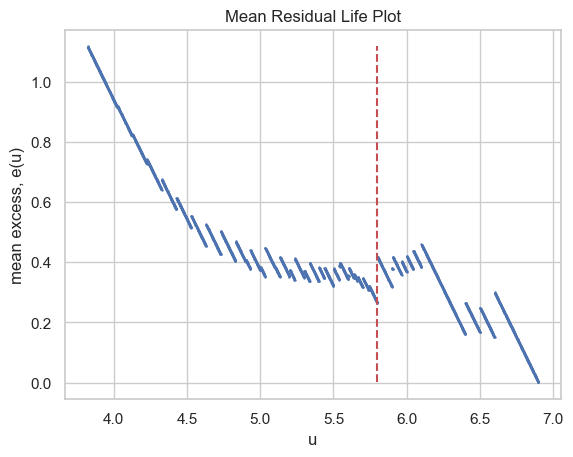

In [415]:
x, y, mag = MRL(dataM7n['Mw'])

In [417]:
threshold = 5.8 # dipilih berdasarkan plot MRLP. 
#Pemilihan ini bersifat subjektif; tiap orang bisa berbeda dalam menerjemahkan plot MRLP

In [419]:
# Import beberapa package dari R untuk melakukan analisis POT dan estimasi parameter GPD 
# Hal ini sebenarnya dapat dilakukan di Python itu sendiri, tanpa melibatkan R
# Jika Anda dapat melakukan proses estimasi parameter GPD tanpa menggunakan package dari R, itu akan menjadi poin plus
# Import beberapa package dari R untuk melakukan MLE
import os
os.environ["R_HOME"] = r"F:/R-4.3.2"  # Pastikan tidak ada karakter aneh seperti ‪
import rpy2
from rpy2.robjects.packages import importr
from rpy2.robjects.vectors import FloatVector
from rpy2.robjects.packages import importr
import rpy2.robjects.packages as rpackages

In [421]:
import warnings
def function_that_warns():
    
    warnings.warn("deprecated", DeprecationWarning)

In [423]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    function_that_warns() # Tidak dilihat sebagai warning

In [425]:
base = importr("base")
utils = importr("utils")
utils.chooseCRANmirror(ind = 1)
#utils.install_packages("POT") # Install package POT

<rpy2.rinterface_lib.sexp.NULLType object at 0x0000023475253790> [0]

In [427]:
POT = importr('POT') # Importing package POT

In [429]:
# Proses estimasi parameter GPD
def gpdfit(sample, threshold, fit_method):
    
    sample = np.sort(sample)
    sample_excess = []
    sample_over_thresh = []
    for data in sample:
        if data > threshold + 0.00001:
            sample_excess.append(data - threshold) # Mendapatkan array excess
            sample_over_thresh.append(data) # Mendapatkan array dengan nilai - nilai di atas threshold
    rdata = FloatVector(sample)
    fit = POT.fitgpd(rdata, threshold, est= fit_method) # Fit data terhadap distribusi
    shape = fit[0][1]
    scale = fit[0][0]
    print(fit)
    
    return shape, scale

In [431]:
shape, scale = gpdfit(dataM7n['Mw'], threshold, "mle") # Estimasi parameter. Lihat prosesnya di console

Estimator: MLE 
 Deviance: 1.350711 
      AIC: 5.350711 

Varying Threshold: FALSE 

  Threshold Call: 5.8 
    Number Above: 12 
Proportion Above: 0.0396 

Estimates
  scale    shape  
 0.6605  -0.5289  

Standard Error Type: observed 

Standard Errors
 scale   shape  
0.2824  0.3504  

Asymptotic Variance Covariance
       scale     shape   
scale   0.07974  -0.09480
shape  -0.09480   0.12276

Optimization Information
  Convergence: successful 
  Function Evaluations: 35 
  Gradient Evaluations: 9 




#### Uji Cramer von Mises

In [434]:
# Uji untuk melihat apakah parameter dan model GPD telah baik dalam mendekati data
frozen_dist = stats.genpareto(shape, threshold, scale )
uji = stats.cramervonmises(dataM7n['Mw'][dataM7n['Mw'] > threshold], frozen_dist.cdf) # Kita gunakan uji Cramer von Mises

In [436]:
uji.statistic, uji.pvalue

(0.07479023779975097, 0.7317048194062863)

#### P value > 0.05 maka gagal tolak h0 artinya data berdistribusi GPD

Lihat statistik uji dan p-valuenyadi variabel uji
uji.statistic, uji.pvalue  # Jika p-value > alfa (misal 0.05), estimasi parameter dan model GPD dapat digunakan

In [440]:
# Parameter GPD yang diperoleh
loc = threshold # 5.8
scale = scale 
shape = shape

----------------------------------------------------------------------
Simulasi Monte Carlo: Membangkitkan data Mw 

In [443]:
# Data yang dibangkitkan adalah 1000 nilai Mw berdistribusi GPD untuk tiap karakteristik dari 685 gempa (latitude, longitude, dan kedalaman)
# Jadi, kita akan mempunyai 685*1000 = 685.000 data Mw
# Hasil pembangkitan data disimpan di data14_monte
n = 1000
dataM7n_monte = pd.DataFrame(np.repeat(dataM7n.values, n, axis = 0))
dataM7n_monte = dataM7n_monte.set_axis(["Event ID", "Latitude", "Longitude", "Kedalaman (km)", "Mw", "Tipe Gempa"], axis = 1)

In [445]:
EventID2 = []
Mw = []
for i in range(1, len(dataM7n)+1, 1):
    Mw.append(genpareto.rvs(shape, loc = loc, scale = scale, size = n, random_state = i))
    for j in range(1, n+1, 1):
        EventID2.append(str(i) + ";" + str(j))

In [446]:
dataM7n_monte.drop("Event ID", axis = 1, inplace = True)
dataM7n_monte.drop("Mw", axis = 1, inplace = True)

In [449]:
dataM7n_monte.insert(0, "Event ID", EventID2)
dataM7n_monte.insert(4, "Mw", np.array(Mw).ravel())
dataM7n_monte

,Event ID,Latitude,Longitude,Kedalaman (km),Mw,Tipe Gempa
0,1;1,-7.2822,104.7907,49.0,6.110047,Interface
1,1;2,-7.2822,104.7907,49.0,6.412232,Interface
2,1;3,-7.2822,104.7907,49.0,5.800076,Interface
3,1;4,-7.2822,104.7907,49.0,6.016511,Interface
4,1;5,-7.2822,104.7907,49.0,5.900544,Interface
...,...,...,...,...,...,...
302995,303;996,-7.569,104.552,33.0,6.443823,Interface
302996,303;997,-7.569,104.552,33.0,6.186982,Interface
302997,303;998,-7.569,104.552,33.0,6.178766,Interface
302998,303;999,-7.569,104.552,33.0,6.662340,Interface


--------------------------------------------------------------------------------------------------------------------------
# Inventory module

In [452]:
# Mengimpor data bangunan beserta detailnya yang ada pada lokasi tertentu
# Data yang digunakan adalah data bangunan di Prov. Papua Barat, Kota Sorong
# Data ini harus sudah ada kolom vs30; jika belum ada, ditambahkan dahulu di QGIS
inventory = pd.read_excel(r'../data/inventory/PROV BANTEN-fix.xlsx', sheet_name = 'KOTA TANGERANG')
inventory
inventory_excel_file = pd.ExcelFile(r'../data/inventory/PROV BANTEN-fix.xlsx')

In [453]:
print("Banyak kota/kabupaten: ", len(inventory_excel_file.sheet_names))
print(inventory_excel_file.sheet_names)

Banyak kota/kabupaten:  8
['KAB. PANDEGLANG', 'KAB. LEBAK', 'KAB. TANGERANG', 'KAB. SERANG', 'KOTA TANGERANG', 'KOTA CILEGON', 'KOTA SERANG', 'KOTA TANGERANG SELATAN']


----------------------------------------------------------------------
Proses perhitungan GMPE/fungsi atenuasi. Tujuannya untuk mendapatkan Spectral Acceleration (SA)

Terdapat 3 fungsi atenuasi: 
1) Atkinson-Boore, 2) Zhao, dan 3) BC Hydro, jadi kita akan mendapatkan 3 nilai SA

In [458]:
# Step 1: membentuk fungsi yang menghitung jarak antara lokasi bangunan dan sumber gempa
def surf_dist (lat1, lon1, lat2, lon2):
# lat1, lon1: koordinat lokasi bangunan
# lat2, lon2: koordinat sumber gempa

    r = 6371 # jari-jari bumi
    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)
    a = asin((sin((lat1 - lat2)/2)**2 + cos(lat2)*cos(lat1)*sin((lon1 - lon2)/2)**2)**0.5)
    
    return 2*r*a

In [460]:
# Step 2: Hitung jarak untuk setiap sheet (Kab - Kota)
surface_distance = pd.DataFrame()

In [462]:
for j in range (len(inventory_excel_file.sheet_names)):
    lat1 = inventory_excel_file.parse(j)['lat'][0]
    lon1 = inventory_excel_file.parse(j)['lon'][0]
    eventj = []
    for i in range (len(dataM7n)):
        lat2 = dataM7n['Latitude'][i]
        lon2 = dataM7n['Longitude'][i]
        eventj.append(surf_dist(lat1, lon1, lat2, lon2))
    surface_distance = pd.concat([surface_distance, pd.DataFrame(eventj, columns=[inventory_excel_file.sheet_names[j]])], axis = 1)

In [464]:
surface_distance["KOTA TANGERANG"]

0      238.759607
1      167.870688
2      141.444479
3      142.597857
4      133.892723
          ...    
298    100.828242
299    258.959813
300    183.644752
301    175.356590
302    278.097645
Name: KOTA TANGERANG, Length: 303, dtype: float64

In [466]:
surface_distance["KOTA TANGERANG"]

0      238.759607
1      167.870688
2      141.444479
3      142.597857
4      133.892723
          ...    
298    100.828242
299    258.959813
300    183.644752
301    175.356590
302    278.097645
Name: KOTA TANGERANG, Length: 303, dtype: float64

In [468]:
# Step 3: membentuk fungsi jarak rupture antara lokasi bangunan dan sumber gempa
def rrup(surf_dist, depth):
    
    r = 6371
    teta = surf_dist/r
    straight_dist = 2*r*np.sin(teta/2)
    return np.sqrt(straight_dist **2 + depth **2)

In [470]:
len(surface_distance)

303

In [472]:
rupture_distance = surface_distance.copy()
start = time.time()

In [474]:
for j in range(len(surface_distance.columns)):
   # Columns represents Kab - Kota
   for i in range (len(surface_distance)):
       # Row represents the earthquake (source) id
       rupture_distance[rupture_distance.columns [j]][i] = rrup (rupture_distance[rupture_distance.columns[j]][i], dataM7n["Kedalaman (km)"][i])

C:\Users\USER\AppData\Local\Temp\ipykernel_2932\75135734.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  rupture_distance[rupture_distance.columns [j]][i] = rrup (rupture_distance[rupture_distance.columns[j]][i], dataM7n["Kedalaman (km)"

In [476]:
end = time.time()
print("Runtime: " + str(round(end - start, 2)) + " detik")

Runtime: 2.04 detik


In [478]:
rupture_distance["KOTA TANGERANG"]

0      243.722133
1      171.078746
2      152.124025
3      158.717958
4      137.897069
          ...    
298    101.321875
299    261.036305
300    273.440706
301    178.809934
302    280.026822
Name: KOTA TANGERANG, Length: 303, dtype: float64

In [480]:
rupture_distance["KOTA TANGERANG"]

0      243.722133
1      171.078746
2      152.124025
3      158.717958
4      137.897069
          ...    
298    101.321875
299    261.036305
300    273.440706
301    178.809934
302    280.026822
Name: KOTA TANGERANG, Length: 303, dtype: float64

In [482]:
# Mengimpor parameter - parameter fungsi atenuasi
par_AB03 = pd.ExcelFile('../data/gmpe/Koef_GMPE_AB03.xlsx')
par_Zhao06 = pd.read_excel('../data/gmpe/Koef_GMPE_Zhao06.xlsx')
par_BCH12 = pd.ExcelFile('../data/gmpe/Koef_GMPE_BCH12.xlsx')

In [484]:
Kab_Kota = 'KOTA TANGERANG'
num_monte_simul = 1000

----------------------------------------------------------------------
Class untuk fungsi atenuasi Atkinson dan Boore (2003)

In [487]:
class AB03 :
    
    """
    Kelas ini menghitung nilai spectral acceleration (SA) dengan GMPE Atkinson Boore (2003) pada data properti kabupaten/kota
    untuk satu megathrust. Data yang diperlukan adalah
        - kab_kota : nama kabupaten/kota
        - inventory : data inventori properti di kabupaten/kota terkait
        - mag_monte : data moment magnitude yang dibangkitkan 10 ,000 kali dengan GPD
        - rupture : data jarak rupture antara site dengan sumber gempa
        - par_AB03 : koefisien GMPE Atkinson Boore (2003)
    !!! PENTING !!! Jika ada periode inventori yang 0.2s ataupun 0.4 s maka kelas ini harus diubah sesuai Erratum .
    """

    def __init__(self, kab_kota, inventory, mag_monte, rupture, par_AB03, num_monte_simul):

        self.par_inter_AB03 = inventory[['period']].merge(par_AB03.parse(0), on = 'period', how = 'left')
        self.par_intra_AB03 = inventory[['period']].merge(par_AB03.parse(1), on= 'period', how = 'left')
        self.rrup = np.repeat(rupture[[kab_kota]].to_numpy(), num_monte_simul, axis = 0)
        self.depth = np.minimum(mag_monte[['Kedalaman (km)']].to_numpy(), 100) # kedalaman maks 100 km
        self.tipe = mag_monte[['Tipe Gempa']].to_numpy()

        mag = mag_monte[['Mw']].to_numpy()
        mag[self.tipe == 'Interface'] = np.minimum(mag, 8.5)[self.tipe == 'Interface'] # magnitude interface maks 8.5
        mag[self.tipe == 'Intraslab'] = np.minimum(mag, 8.0)[self.tipe == 'Intraslab'] # magnitude intraslab maks 8.0
        self.mag = mag

        # Magnitude term (fn(m) = c1 + c2*m)
        fn_inter = np.dot(self.mag, self.par_inter_AB03[['c2']].to_numpy().T) + np.repeat(self.par_inter_AB03[['c1']].to_numpy().T, len(mag_monte), axis = 0)
        fn_inter[np.repeat(self.tipe, len(inventory), axis =1) == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface
        
        fn_intra = np.dot(self.mag, self.par_intra_AB03[['c2']].to_numpy().T) + np.repeat(self.par_intra_AB03[['c1']].to_numpy().T, len(mag_monte), axis = 0)
        fn_intra[np.repeat(self.tipe, len(inventory), axis = 1) == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab
        
        self .fn = fn_inter + fn_intra

        # Depth term (c3*h)
        depth_inter = np.dot(self.depth, self.par_inter_AB03[['c3']].to_numpy().T)
        depth_inter[np.repeat(self.tipe, len(inventory), axis = 1) == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        depth_intra = np.dot(self.depth, self.par_intra_AB03[['c3']].to_numpy().T)
        depth_intra[np.repeat(self.tipe, len(inventory), axis = 1) == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab
        
        self.c3_h = depth_inter + depth_intra

        # Distance term (c4*R - g* log10 (R) dengan R = sqrt (r^2 + delta ^2)
        self.delta = 0.00724*10**(0.507*self.mag)
        self.R = np.sqrt(self.delta**2 + self.rrup**2)

        c4_r_inter = np.dot(self.R, self.par_inter_AB03[['c4']].to_numpy().T)
        c4_r_inter[np.repeat(self.tipe, len(inventory), axis = 1) == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        c4_r_intra = np.dot(self.R, self.par_intra_AB03[['c4']].to_numpy().T)
        c4_r_intra[np.repeat(self.tipe, len(inventory), axis = 1) == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Interslab
        
        g_inter = 10**(1.2 - 0.18*self.mag)
        g_inter[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        g_intra = 10**(0.301 - 0.01*self.mag)
        g_intra[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab
        
        self.distance_term = c4_r_inter + c4_r_intra - np.repeat(g_inter*np.log10(self.R) + g_intra*np.log10(self .R), len(inventory), axis = 1)
        
        """ Menghitung nilai PGA Rock """

        par_inter_PGA = par_AB03.parse(0)[par_AB03.parse(0).period == 'PGA']
        par_intra_PGA = par_AB03.parse(1)[par_AB03.parse(1).period == 'PGA']

        # Magnitude term PGA (fn(m) = c1 + c2*m)
        fn_PGA_inter = np.dot(self.mag, par_inter_PGA[['c2']].to_numpy()) + par_inter_PGA[['c1']].to_numpy()
        fn_PGA_inter[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        fn_PGA_intra = np.dot(self.mag, par_intra_PGA[['c2']].to_numpy()) + par_intra_PGA[['c1']].to_numpy()
        fn_PGA_intra[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        fn_PGA = fn_PGA_inter + fn_PGA_intra
        
        # Depth term PGA (c3*h)
        depth_PGA_inter = np.dot(self.depth, par_inter_PGA[['c3']].to_numpy())
        depth_PGA_inter[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        depth_PGA_intra = np.dot(self.depth, par_intra_PGA[['c3']].to_numpy())
        depth_PGA_intra[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        c3_h_PGA = depth_PGA_inter + depth_PGA_intra
        
        # Distance term PGA (c4*R - g* log10 (R) dengan R= sqrt (r^2 + delta ^2))
        c4_r_PGA_inter = np.dot(self.R, par_inter_PGA[['c4']].to_numpy ())
        c4_r_PGA_inter[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface
        
        # Distance term PGA (c4*R - g* log10 (R) dengan R= sqrt (r^2 + delta ^2))
        c4_r_PGA_intra = np.dot(self.R, par_inter_PGA[['c4']].to_numpy ())
        c4_r_PGA_intra[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab
        
        distance_term_PGA = c4_r_PGA_inter + c4_r_PGA_intra - (g_inter*np.log10(self.R) + g_intra*np.log10(self.R))
        
        # Nilai PGA Rock
        PGA_rock = 10**(fn_PGA + c3_h_PGA + distance_term_PGA)
        self.PGA_rock = np.repeat(PGA_rock, len(inventory), axis = 1)
        
        """ [batas hitung PGA Rock] """

        # Site term (c5*sl*Sc + c6*sl*Sd + c7*sl*Se)
        period = np.repeat(self.par_inter_AB03 [['period']].to_numpy().T, len(mag_monte), axis =0) 
        
        # Nilai periode inventori sama , terlepas dari interface / intraslab
        period [np.where(period == 'PGA')] = 0

        sl = np.zeros((len(mag_monte), len(inventory)))

        cond1 = np.where((period >= 1.0) | (self.PGA_rock <= 100) ,True ,False)
        cond2 = np.where(((period > 0.5) & (period < 1)) & ((self.PGA_rock > 100) & (self.PGA_rock < 500)), True, False)
        cond3 = np.where(((period > 0.5) & (period < 1)) & ( self.PGA_rock >= 500), True, False )
        cond4 = np.where((period <= 0.5) & ((self.PGA_rock > 100) & (self.PGA_rock < 500)), True, False)

        sl[cond1] = 1
        sl[cond2] = 1 - (1/period[cond2] - 1)*(self.PGA_rock[cond2] -100)/400
        sl[cond3] = 1 - (1/period[cond3] - 1)
        sl[cond4] = 1 - (self.PGA_rock[cond4] - 100)/400
        self.sl = sl
        
        sl_inter = self.sl.copy()
        sl_inter[np.repeat(self.tipe, len(inventory), axis = 1) == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface
        
        sl_intra = self.sl.copy()
        sl_intra[np.repeat(self.tipe, len(inventory), axis = 1) == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        self.vs30 = inventory['vs30'].values[0] # nilai vs30 sama untuk satu kabupaten / kota

        if 360 < self.vs30 <= 760:
            self.site_term = sl_inter*self.par_inter_AB03[['c5']].to_numpy().flatten() + sl_intra*self.par_intra_AB03[['c5']].to_numpy().flatten()
        elif 180 <= self.vs30 <= 360:
            self.site_term = sl_inter*self.par_inter_AB03[['c6']].to_numpy().flatten() + sl_intra*self.par_intra_AB03[['c6']].to_numpy().flatten()  
        elif self.vs30 < 180:
            self.site_term = sl_inter*self.par_inter_AB03[['c7']].to_numpy().flatten() + sl_intra*self.par_intra_AB03[['c7']].to_numpy().flatten()
        else:
            self.site_term = 0

    def compute(self):
        self.log_y = (self.fn + self.c3_h + self.distance_term + self.site_term).astype(np.float32)
        return (10**(self.log_y))/980.665 # dalam g = 980.665 cm/s^2

----------------------------------------------------------------------
Class untuk fungsi atenuasi Zhao et al. (2006)

In [490]:
class Zhao06:
    
    """
    Kelas ini menghitung nilai spectral acceleration (SA) dengan GMPE Zhao (2006) pada data properti kabupaten/kota
    untuk satu megathrust. Data yang diperlukan adalah
        - kab_kota : nama kabupaten/kota
        - inventory : data inventori properti di kabupaten/kota terkait
        - mag_monte : data moment magnitude yang dibangkitkan 10 ,000 kali dengan GPD
        - rupture : data jarak rupture antara site dengan sumber gempa
        - par_Zhao : koefisien GMPE Zhao (2006)
    """

    def __init__(self, kab_kota, inventory, mag_monte, rupture, par_Zhao06, num_monte_simul):

        self.par_Zhao06 = inventory[['period']].merge(par_Zhao06, on = 'period', how = 'left')
        self.mag = mag_monte[['Mw']].to_numpy()
        self.rrup = np.repeat(rupture[[kab_kota]].to_numpy(), num_monte_simul, axis = 0)
        self.depth = np.minimum(mag_monte[['Kedalaman (km)']].to_numpy(), 125) # kedalaman maks 125 km
        self.tipe = np.repeat(mag_monte[['Tipe Gempa']].to_numpy(), len(inventory), axis = 1)

        # Magnitude term (a*Mw)
        self.mag_term = np.dot(self.mag, self.par_Zhao06[['a']].to_numpy().T)

        # Distance term (b*x - ln(r) dengan r = x + c*exp (d*Mw))
        self.r = np.repeat(self.rrup, len(inventory), axis = 1) + np.exp(np.dot(self.mag, self.par_Zhao06[['d']].to_numpy().T))*self.par_Zhao06['c'].to_numpy()
        self.distance_term = np.dot(self.rrup, self.par_Zhao06[['b']].to_numpy().T) - np.log(self.r)

        # Depth term (e*(h - hc) untuk h >= hc, 0 untuk h < hc)
        hc = 15
        self.depth_term = np.dot(np.where(self.depth - hc < 0, 0, self.depth - hc), self.par_Zhao06[['e']].to_numpy().T)
        
        # S term (SI + SS + SSL*ln(x))
        self.SI = np.repeat(self.par_Zhao06[['SI']].to_numpy().T, len(mag_monte), axis = 0)
        self.SI[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        self.SS = np.repeat(self.par_Zhao06[['SS']].to_numpy ().T, len(mag_monte), axis = 0)
        self.SS[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        self.SSL = np.dot(np.log(self.rrup), self.par_Zhao06[['SSL']].to_numpy ().T)
        self.SSL[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        self.S_term = self.SI + self.SS + self.SSL
        
        # Site - class term (Ck)
        self.vs30 = inventory ['vs30'].values [0] # nilai vs30 sama untuk satu kabupaten / kota

        if self.vs30 > 1100:
            site_term = self.par_Zhao06[['CH']].to_numpy()
        elif 600 < self.vs30 <= 1100:
            site_term = self.par_Zhao06[['C1']].to_numpy()
        elif 300 < self.vs30 <= 600:
            site_term = self.par_Zhao06[['C2']].to_numpy()
        elif 200 < self.vs30 <= 300:
            site_term = self.par_Zhao06[['C3']].to_numpy()
        else:
            site_term = self.par_Zhao06[['C4']].to_numpy()
            
        self.site_term = np.repeat(site_term.T, len(mag_monte), axis = 0)
        
        # Magnitude squared term error
        magsq_inter = np.dot((self.mag - 6.3)**2 , self.par_Zhao06[['QI']].to_numpy().T) + np.repeat(self.par_Zhao06[['WI']].to_numpy().T, len(mag_monte), axis = 0)
        magsq_inter[self.tipe == 'Intraslab'] = 0 # nilai != 0 hanya untuk kejadian Interface

        magsq_intra = np.dot(self.mag - 6.5, self.par_Zhao06[['PS']].to_numpy().T) + np.dot((self.mag - 6.5)**2 , self.par_Zhao06[['QS']].to_numpy().T) + np.repeat(self.par_Zhao06[['WS']].to_numpy().T, len(mag_monte), axis = 0)
        magsq_intra[self.tipe == 'Interface'] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        self.magsq_term = magsq_inter + magsq_intra
        
    def compute(self):
        self.ln_y = (self.mag_term + self.distance_term + self.depth_term + self.S_term + self.site_term + self.magsq_term).astype(np.float32)
        return np.exp(self.ln_y)/980.665 # dalam g = 980.665 cm/s^2

----------------------------------------------------------------------
Class untuk fungsi atenuasi BCHydro (2012)

In [493]:
class BCH12:

    """
    Kelas ini menghitung nilai spectral acceleration (SA) dengan GMPE BCHydro (2012) pada data properti kabupaten/kota
    untuk satu megathrust. Data yang diperlukan adalah
        - kab_kota: nama kabupaten/kota
        - inventory: data inventori properti di kabupaten/kota terkait
        - mag_monte: data moment magnitude yang dibangkitkan 10 ,000 kali dengan GPD
        - rupture: data jarak rupture antara site dengan sumber gempa
        - par_BCH12: koefisien GMPE BCHydro (2006)
        - site_type: tipe site (forearc/backarc)
        - dC1_type: asumsi nilai epistemic uncertainty dalam magnitude scaling (lower/central/upper)
    """

    def __init__(self, kab_kota, inventory, mag_monte, rupture, par_BCH12, site_type, dC1_type, num_monte_simul):

        self.par_BCH12 = inventory[['period']].merge(par_BCH12.parse(0), on = 'period', how = 'left')
        self.mag = mag_monte[['Mw']].to_numpy()
        self.rrup = np.repeat(rupture[[kab_kota]].to_numpy(), num_monte_simul, axis = 0)
        self.depth = mag_monte[['Kedalaman (km)']].to_numpy() # kedalaman maks 125 km
        self.tipe = np.repeat(mag_monte[['Tipe Gempa']].to_numpy(), len(inventory), axis = 1)

        dC1_inter = np.repeat(inventory[['period']].merge(par_BCH12.parse(1), on = 'period', how = 'left')[[dC1_type + 'I']].to_numpy().T, len(mag_monte), axis = 0)
        dC1_inter[self.tipe == "Intraslab"] = 0 # nilai != 0 hanya untuk kejadian Interface

        dC1_intra = np.repeat(inventory[['period']].merge(par_BCH12.parse(1), on= 'period', how = 'left')[[dC1_type + 'S']].to_numpy().T, len(mag_monte), axis = 0)
        dC1_intra[self.tipe == "Interface"] = 0 # nilai != 0 hanya untuk kejadian Intraslab

        self.dC1 = dC1_inter + dC1_intra
        
        # Magnitude term ( theta1 + theta4 *dc1 + fmag (M))
        mag_term = np.repeat(self.par_BCH12[['theta1']].to_numpy().T, len(mag_monte), axis = 0) + self.par_BCH12[['theta4']].to_numpy().T*self.dC1
        
        fmag_cond1 = self.par_BCH12[['theta4']].to_numpy().T*(np.repeat(self.mag, len(inventory), axis = 1) - (7.8 + self.dC1)) + np.dot((10 - self.mag)**2, self.par_BCH12[['theta13']].to_numpy().T)
        fmag_cond1[np.repeat(self.mag, len(inventory), axis = 1) > 7.8 + self.dC1] = 0

        fmag_cond2 = self.par_BCH12[['theta5']].to_numpy().T*(np.repeat(self.mag, len(inventory), axis = 1) - (7.8 + self.dC1)) + np.dot((10 - self.mag)**2, self.par_BCH12[['theta13']].to_numpy().T)
        fmag_cond2[np.repeat(self.mag, len(inventory), axis = 1) <= 7.8 + self.dC1] = 0

        self.mag_term = mag_term + (fmag_cond1 + fmag_cond2)

        # Distance term (( theta2 + theta14 * F_event + theta3 *(M-7.8) ) * ln(r + C4*exp ( theta9 *(M -6)))) + theta6 *r + theta10 *F_event
        self.F_event = np.where(self.tipe == 'Interface', 0, 1)

        self.distance_term = (np.repeat(self.par_BCH12[['theta2']].to_numpy().T, len(mag_monte), axis = 0) + self.par_BCH12[['theta14']].to_numpy().T*self.F_event + np.dot(self.mag -7.8,self.par_BCH12[['theta3']].to_numpy().T))* \
                np.log(np.repeat(self.rrup, len(inventory), axis = 1) + self.par_BCH12[['C4']].to_numpy().T*np.exp(np.dot(self.mag -6, self.par_BCH12[['theta9']].to_numpy().T))) + \
                np.dot(self.rrup, self.par_BCH12[['theta6']].to_numpy().T) + self.par_BCH12[['theta10']].to_numpy().T*self.F_event

        # Depth term ( fdepth = theta11 *( min(h ,120) -60)* F_event )
        self.depth_term = np.dot(np.minimum(self.depth, 120) - 60, self.par_BCH12[['theta11']].to_numpy().T)*self.F_event

        # FABA term ( f_FABA )
        FFABA = 1 if site_type == 'backarc' else 0

        f_FABA_cond1 = np.repeat(self.par_BCH12[['theta7']].to_numpy().T, len(mag_monte), axis = 0) + np.dot(np.maximum(self.rrup, 85)/40, self.par_BCH12[['theta8']].to_numpy().T)*FFABA
        f_FABA_cond1[self. F_event == 0] = 0

        f_FABA_cond2 = np.repeat(self.par_BCH12[['theta15']].to_numpy().T, len(mag_monte), axis = 0) + np.dot(np.maximum(self.rrup, 100)/40, self.par_BCH12[['theta16']].to_numpy().T)*FFABA
        f_FABA_cond2 [ self . F_event == 1] = 0

        self.f_FABA = f_FABA_cond1 + f_FABA_cond2
        
        """ Menghitung nilai PGA1000 """

        par_PGA = par_BCH12.parse(0)[par_BCH12.parse(0).period == 'PGA']
        dC1_PGA_inter = par_BCH12.parse(1)[par_BCH12.parse(1).period == 'PGA'][[dC1_type + 'I']].to_numpy()
        dC1_PGA_intra = par_BCH12.parse(1)[par_BCH12.parse(1).period == 'PGA'][[dC1_type + 'S']].to_numpy()
        dC1_PGA = np.where(mag_monte[['Tipe Gempa']].to_numpy() == 'Interface', dC1_PGA_inter, dC1_PGA_intra)
        
        # Magnitude term PGA 1000 ( theta1 + theta4 *dc1 + fmag (M))
        mag_term_PGA = par_PGA[['theta1']].to_numpy() + par_PGA[['theta4']].to_numpy()*dC1_PGA

        fmag_PGA_cond1 = par_PGA[['theta4']].to_numpy()*(self.mag - (7.8 + dC1_PGA)) + par_PGA[['theta13']].to_numpy()*(10 - self.mag)**2
        fmag_PGA_cond1[self.mag > 7.8 + dC1_PGA] = 0

        fmag_PGA_cond2 = par_PGA[['theta5']].to_numpy()*(self.mag - (7.8 + dC1_PGA)) + par_PGA[['theta13']].to_numpy()*(10 - self.mag)**2
        fmag_PGA_cond2[self.mag <= 7.8 + dC1_PGA] = 0

        mag_term_PGA = mag_term_PGA + (fmag_PGA_cond1 + fmag_PGA_cond2)
        
        # Distance term PGA 1000 (( theta2 + theta14 * F_event + theta3 *(M -7.8) ) * ln(r + C4*exp ( theta9 *(M -6)))) + theta6 *r + theta10 * F_event
        distance_term_PGA = (par_PGA[['theta2']].to_numpy() + par_PGA[['theta14']].to_numpy()*self.F_event[:, [1]] + par_PGA[['theta3']].to_numpy()*(self.mag - 7.8))* \
                np.log(self.rrup + par_PGA[['C4']].to_numpy()*np.exp(par_PGA[['theta9']].to_numpy()*(self.mag - 6))) + \
                par_PGA[['theta6']].to_numpy()*self.rrup + par_PGA[['theta10']].to_numpy()*self.F_event[:, [1]]

        # Depth term PGA 1000 ( fdepth = theta11 *( min(h ,120) -60)*F_event )
        depth_term_PGA = par_PGA[['theta11']].to_numpy()*(np.minimum(self.depth, 120) - 60)*self.F_event[:, [1]]
        
        # FABA term PGA 1000 ( f_FABA )
        f_FABA_PGA_cond1 = par_PGA[['theta7']].to_numpy() + par_PGA[['theta8']].to_numpy()*np.log(np.maximum(self.rrup, 85)/40)*FFABA
        f_FABA_PGA_cond1[self.F_event[:, [1]] == 0] = 0

        f_FABA_PGA_cond2 = par_PGA[['theta15']].to_numpy() + par_PGA[['theta16']].to_numpy()*np.log(np.maximum(self.rrup, 100)/40)*FFABA
        f_FABA_PGA_cond2[self.F_event[:, [1]] == 1] = 0

        f_FABA_PGA = f_FABA_PGA_cond1 + f_FABA_PGA_cond2
        
        # Site Term PGA 1000 ( fsite )
        fsite_PGA = (par_PGA[['theta12']].to_numpy() + par_PGA[['b']].to_numpy()*par_PGA[['n']].to_numpy())*np.log(1000/par_PGA[['Vlin']].to_numpy())
        
        # Nilai PGA 1000
        PGA1000 = (mag_term_PGA + distance_term_PGA + depth_term_PGA + f_FABA_PGA + fsite_PGA).astype(np.float32)
        self.PGA1000 = np.repeat(np.exp(PGA1000), len(inventory), axis = 1)

        """ batas hitung PGA1000 """

        self.vs30 = inventory['vs30'].values[0] # nilai vs30 sama untuk satu kabupaten / kota
        self.Vstar = min(self.vs30, 1000)

        fsite_cond1 = np.repeat(self.par_BCH12[['theta12']].to_numpy().T*np.log(self.Vstar/self.par_BCH12[['Vlin']].to_numpy().T), len(mag_monte), axis = 0) - self.par_BCH12[['b']].to_numpy().T*np.log(self.PGA1000 + self.par_BCH12[['c']].to_numpy().T) + \
                self.par_BCH12[['b']].to_numpy().T*np.log(self.PGA1000 + self.par_BCH12[['c']].to_numpy().T*(self.Vstar/self.par_BCH12[['Vlin']].to_numpy().T)**self.par_BCH12[['n']].to_numpy().T)
        fsite_cond1[self.vs30 >= np.repeat(self.par_BCH12[['Vlin']].to_numpy().T, len(mag_monte), axis = 0)] = 0

        fsite_cond2 = np.repeat((self.par_BCH12[['theta12']].to_numpy().T + self.par_BCH12[['b']].to_numpy().T*self.par_BCH12[['n']].to_numpy().T)*np.log(self.Vstar/self.par_BCH12[['Vlin']].to_numpy().T), len(mag_monte), axis = 0)
        fsite_cond2[self.vs30 < np.repeat(self.par_BCH12[['Vlin']].to_numpy().T, len (mag_monte), axis = 0)] = 0

        self.fsite = fsite_cond1 + fsite_cond2
        
    def compute(self):
        self.ln_y = (self.mag_term + self.distance_term + self.depth_term + self.f_FABA + self.fsite).astype(np. float32)
        return np.exp(self.ln_y) # dalam g

----------------------------------------------------------------------
 Menghitung SA pada data inventory dengan tiga fungsi atenuasi yang telah dibuat algoritmanya di atas

In [496]:
start = time.time()

In [498]:
SA_AB = AB03(Kab_Kota, inventory, dataM7n_monte, rupture_distance, par_AB03, num_monte_simul).compute()
SA_Zhao = Zhao06(Kab_Kota, inventory, dataM7n_monte, rupture_distance, par_Zhao06, num_monte_simul).compute() 
SA_BCH = BCH12(Kab_Kota, inventory, dataM7n_monte, rupture_distance, par_BCH12, "forearc", "central", num_monte_simul).compute() 

In [499]:
print(time.time() - start, 'detik')

24.906315803527832 detik


In [502]:
# Nilai SA yang kita gunakan diambil dari rata-rata tiga fungsi atenuasi
SA = pd.DataFrame((SA_AB + SA_Zhao + SA_BCH)/3)
SA

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,0.011924,0.007331,0.011924,0.007331,0.005708,0.011924,0.011924,0.005708,0.011924,0.011924,0.011924,0.011924,0.011924,0.011924,0.011924,0.011924,0.011924
1,0.019096,0.012143,0.019096,0.012143,0.009159,0.019096,0.019096,0.009159,0.019096,0.019096,0.019096,0.019096,0.019096,0.019096,0.019096,0.019096,0.019096
2,0.007437,0.004410,0.007437,0.004410,0.003554,0.007437,0.007437,0.003554,0.007437,0.007437,0.007437,0.007437,0.007437,0.007437,0.007437,0.007437,0.007437
3,0.010327,0.006282,0.010327,0.006282,0.004940,0.010327,0.010327,0.004940,0.010327,0.010327,0.010327,0.010327,0.010327,0.010327,0.010327,0.010327,0.010327
4,0.008655,0.005193,0.008655,0.005193,0.004137,0.008655,0.008655,0.004137,0.008655,0.008655,0.008655,0.008655,0.008655,0.008655,0.008655,0.008655,0.008655
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302995,0.013127,0.008589,0.013127,0.008589,0.006600,0.013127,0.013127,0.006600,0.013127,0.013127,0.013127,0.013127,0.013127,0.013127,0.013127,0.013127,0.013127
302996,0.008783,0.005605,0.008783,0.005605,0.004407,0.008783,0.008783,0.004407,0.008783,0.008783,0.008783,0.008783,0.008783,0.008783,0.008783,0.008783,0.008783
302997,0.008672,0.005529,0.008672,0.005529,0.004351,0.008672,0.008672,0.004351,0.008672,0.008672,0.008672,0.008672,0.008672,0.008672,0.008672,0.008672,0.008672
302998,0.018529,0.012378,0.018529,0.012378,0.009316,0.018529,0.018529,0.009316,0.018529,0.018529,0.018529,0.018529,0.018529,0.018529,0.018529,0.018529,0.018529


--------------------------------------------------------------------------------------------------------------------------
# Vulnerability module

In [505]:
# Mengimpor vulnerabilty curve. Dalam project ini kurva vulnerability telah diberikan, tidak menghitung sendiri
from scipy.interpolate import interp1d

In [507]:
# Mengimpor vulnerability curve yang ada pada eksposur-eksposur
taxonomy = os.listdir ('../data/vulnerability/')
taxonomy = [i.strip('.csv') for i in taxonomy]
vuln_curve = {file.split('/')[-1].replace('-', '_'): pd.read_csv('../data/vulnerability/' + file +'.csv') for file in taxonomy}

In [509]:
print('Banyak file taksonomi: ', len(taxonomy))
print([i.replace('-', '_') for i in taxonomy])

Banyak file taksonomi:  20
['CR_LDUAL_DUH_H9', 'CR_LFINF_DUH_H3', 'CR_LFINF_DUH_H4', 'CR_LFINF_DUH_H5', 'CR_LFINF_DUL_H3', 'CR_LFINF_DUL_H4', 'CR_LFINF_DUL_H5', 'CR_LFINF_DUM_H3', 'CR_LFINF_DUM_H4', 'MCF_LWAL_DUL_H1', 'MCF_LWAL_DUL_H2', 'MCF_LWAL_DUL_H3', 'MCF_LWAL_DUM_H1', 'MCF_LWAL_DUM_H2', 'MCF_LWAL_DUM_H3', 'MUR_LWAL_DNO_H1', 'MUR_LWAL_DNO_H2', 'S_LPB_DUC', 'UNK', 'W_WLI_H1']


In [511]:
# Taxonomy yang ada di inventory tetapi tidak ada vulnerability curve -nya
print(list(set(list(inventory['taxonomy']. str.replace('[/+]', '_', regex = True). str.replace(':', '', regex = True))) - set([i.replace('-', '_') for i in taxonomy])))

['UNK_H1', 'W_WO_LN_H1', 'W_WO_LN_H1_HFAPP1', 'W_WBB_LPB_DNO_H1', 'W_WLI_LWAL_DUL_H1']


In [513]:
# Asumsi taksonomi untuk vulnerability curve yang tidak ada
inv_edit = inventory.copy()

In [515]:
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('[/+]', '_', regex = True). str.replace(':', '', regex = True)
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('UNK_H1', 'UNK')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('W_WLI_LWAL_DUL_H1', 'W_WLI_H1')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('W_WO_LN_H1_HFAPP1', 'W_WLI_H1')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('W_WO_LN_H1', 'W_WLI_H1')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('ME_MEO_LN_H1', 'S_LPB_DUC')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('W_WBB_LPB_DNO_H1', 'W_WLI_H1')
inv_edit['taxonomy'] = inv_edit['taxonomy']. str.replace('CR_LDUAL_DUH_HBET_6_12', 'CR_LDUAL_DUH_H9')

----------------------------------------------------------------------
Menghitung kerugian dari tiap bangunan pada inventory module terhadap SA

In [518]:
class convert_financial :

    """
    Kelas ini memberikan nilai kerugian finansial dari properti di kabupaten / kota untuk untuk gempa di satu megathrust .
    Data yang diperlukan adalah
    - inventory : data inventori properti di kabupaten / kota terkait yang mencakup nilai finansial dan taksonomi properti
    - vuln_curve : vulnerability curve dari properti dengan taksonomi tertentu
    - SA : data spectral acceleration (SA) dari properti akibat gempa di kabupaten / kota terkait
    """
    
    def __init__(self ,inventory, vuln_curve, SA):

        self.taxonomy = inventory['taxonomy']
        self.price = inventory['structural']
        self.SA = SA
        self.loss = np.empty((len(SA), 0))

    def compute(self):

        for i, val in enumerate(self.taxonomy):
            self.vuln_curve = pd.concat([pd.DataFrame([[0, 0]], columns = vuln_curve[val].columns), vuln_curve[val]], ignore_index = True)
            if vuln_curve[val].iloc[:, 0].max() < SA.values.max():
                self.vuln_curve = pd.concat([vuln_curve[val], pd.DataFrame([[SA.values.max(), 1]], columns = vuln_curve[val].columns)], ignore_index = True)
            f = interp1d(self.vuln_curve.iloc[:, 0], self.vuln_curve.iloc[: ,1])
            loss = f(self.SA[[i]])*self.price[i]
            self.loss = np.append(self.loss, loss, axis = 1)

        return self.loss

In [520]:
start = time.time()
loss = pd.DataFrame(convert_financial(inv_edit, vuln_curve, SA.astype('float32')).compute())
end = time.time ()

In [522]:
print("Runtime: " + str(round(end - start, 2)) + " detik")
loss # Nilai kerugian untuk tiap bangunan untuk tiap simulasi berdasarkan nilai SA

Runtime: 0.69 detik


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,6.426046e+06,1.297378e+07,8.859953e+05,2.925036e+06,1.347626,3.657171e+07,411802.042593,0.000056,36936.861756,61088.840606,1.319629e+07,1.297039e+08,127615.357683,1481.361068,2058.312221,6845.447461,4787.135241
1,1.029141e+07,2.148812e+07,1.418935e+06,4.844658e+06,2.162146,5.857016e+07,659507.220335,0.000090,59154.944622,97834.705257,2.113407e+07,2.077227e+08,204377.931901,2372.422230,3296.418257,10963.087989,7666.669733
2,4.007934e+06,7.803668e+06,5.525965e+05,1.759396e+06,0.839062,2.280983e+07,256841.484928,0.000035,23037.570096,38101.191618,8.230546e+06,8.089648e+07,79593.869328,923.926880,1283.772086,4269.514740,2985.742654
3,5.565640e+06,1.111614e+07,7.673662e+05,2.506218e+06,1.166302,3.167500e+07,356664.394714,0.000049,31991.253268,52909.437314,1.142940e+07,1.123374e+08,110528.481155,1283.016338,1782.717438,5928.886025,4146.168587
4,4.664295e+06,9.190398e+06,6.430927e+05,2.072045e+06,0.976713,2.654529e+07,298903.273493,0.000041,26810.330570,44340.854445,9.578426e+06,9.414454e+07,92628.603587,1075.234279,1494.009735,4968.714195,3474.704460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302995,7.074305e+06,1.519905e+07,9.753744e+05,3.426740e+06,1.558178,4.026106e+07,453344.562525,0.000065,40663.046080,67251.472443,1.452753e+07,1.427884e+08,140489.173235,1630.800520,2265.954407,7536.015035,5270.060628
302996,4.733337e+06,9.918677e+06,6.526120e+05,2.236241e+06,1.040362,2.693822e+07,303327.727223,0.000043,27207.184930,44997.200750,9.720209e+06,9.553809e+07,93999.719285,1091.150212,1516.124505,5042.262557,3526.138052
302997,4.673306e+06,9.785020e+06,6.443351e+05,2.206107e+06,1.027078,2.659657e+07,299480.710378,0.000043,26862.124161,44426.514413,9.596931e+06,9.432641e+07,92807.548339,1077.311473,1496.895941,4978.313016,3481.417075
302998,9.985762e+06,2.190423e+07,1.376793e+06,4.938474e+06,2.199233,5.683066e+07,639920.231860,0.000092,57398.076489,94929.070284,2.050640e+07,2.015535e+08,198308.023834,2301.962642,3198.516513,10637.490526,7438.974012


In [524]:
# menghitung total kerugian dari seluruh 27 bangunan untuk tiap simulasi
total_loss = pd.DataFrame(np.reshape(loss.values.sum(axis = 1), (loss.shape[0]//num_monte_simul, num_monte_simul)).T)
# Kemudian tiap 1000 baris dijadikan 1000 kolom, karena 1000 baris berasal dari satu atribut gempa (lihat data_monte)
total_loss # Diperoleh tabel berukuran 685 x 1000, lalu di-transpose. Diperoleh total_loss

,0,1,2,3,4,5,6,7,8,9,...,293,294,295,296,297,298,299,300,301,302
0,2.033354e+08,3.754177e+08,2.063825e+09,7.435552e+10,4.264074e+08,1.330508e+09,3.658856e+08,5.890500e+09,3.604701e+08,2.083304e+08,...,2.055800e+09,6.172207e+08,2.865531e+08,2.654785e+08,2.315584e+08,6.758022e+08,1.633246e+08,4.647259e+08,4.691595e+08,2.268506e+08
1,3.265152e+08,2.358492e+08,5.853935e+09,2.866069e+09,3.708053e+09,3.602856e+08,1.417323e+09,1.998626e+10,6.321920e+08,7.407052e+07,...,5.265407e+08,4.158631e+08,5.250920e+08,5.843052e+07,1.909026e+08,7.785039e+08,1.227775e+08,6.454263e+08,6.714896e+08,1.123658e+08
2,1.264675e+08,4.391885e+08,7.360349e+08,8.111969e+10,4.193194e+08,7.770184e+08,5.520216e+08,5.631134e+09,6.269515e+08,1.611912e+08,...,1.410917e+09,7.427272e+08,8.235702e+08,5.962313e+07,2.398307e+08,1.095295e+09,1.466548e+08,7.294421e+08,3.112674e+08,1.609075e+08
3,1.759624e+08,3.750875e+08,1.581267e+09,8.429743e+09,6.698700e+09,2.620335e+08,8.469725e+08,7.029425e+08,4.084590e+08,1.989090e+08,...,4.919729e+08,4.953940e+08,2.342157e+08,5.823785e+07,1.207158e+08,4.211027e+10,1.331848e+08,5.910909e+08,5.623046e+08,2.583652e+08
4,1.473118e+08,3.678662e+08,2.557630e+10,7.405937e+09,5.891856e+08,2.803456e+08,1.821071e+10,4.935328e+08,4.120242e+08,1.308569e+08,...,2.256520e+09,7.270178e+08,3.895019e+08,9.104304e+07,1.058676e+08,5.394197e+10,1.256341e+08,7.831469e+08,3.665534e+08,1.797216e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6.734169e+08,4.725625e+08,6.977098e+08,2.055254e+09,3.550294e+08,2.770558e+08,3.435051e+08,4.331221e+08,2.596881e+10,1.341239e+08,...,5.791885e+09,3.079120e+08,1.634581e+09,1.327381e+08,1.523366e+08,4.632611e+09,1.226594e+08,3.772057e+08,3.512737e+09,2.249709e+08
996,1.779676e+08,3.404614e+08,2.446652e+09,2.425438e+09,7.663674e+08,2.936754e+08,4.383173e+09,4.111329e+08,8.070933e+08,9.078410e+07,...,2.563235e+09,5.721547e+09,2.487289e+08,2.078591e+08,1.871689e+08,5.051610e+08,4.110601e+08,4.824895e+08,2.935639e+08,1.502181e+08
997,2.972239e+08,5.398268e+08,8.040418e+08,2.701973e+10,3.662063e+09,3.484359e+08,6.879696e+08,7.541797e+08,8.377106e+08,8.631506e+07,...,6.033021e+08,3.401302e+08,3.516425e+08,7.496564e+07,1.835499e+08,6.582952e+08,5.792735e+08,2.672102e+10,6.786635e+08,1.483033e+08
998,1.810919e+08,7.658429e+08,5.697098e+08,7.348552e+08,4.714101e+08,6.485985e+08,7.250997e+08,4.178526e+08,7.478353e+08,1.777879e+08,...,5.905491e+08,5.998792e+08,8.100256e+08,1.277906e+08,1.681057e+08,7.491703e+08,3.901023e+08,9.298150e+08,2.272469e+08,3.181099e+08


In [526]:
total_loss.describe() # Stats deskriptif total kerugian tiap atribut gempa

,0,1,2,3,4,5,6,7,8,9,...,293,294,295,296,297,298,299,300,301,302
count,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,...,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03
mean,2.775301e+08,6.519979e+08,8.917045e+09,1.198097e+10,1.945783e+09,8.570409e+08,2.040953e+09,2.944379e+09,2.284903e+09,1.581936e+08,...,5.421303e+09,1.365211e+09,5.446583e+08,1.217198e+08,2.070702e+08,5.847154e+09,2.104813e+08,1.710159e+09,5.784814e+08,1.835271e+08
std,1.461987e+08,9.239364e+08,1.745380e+10,2.177287e+10,4.062980e+09,1.387915e+09,4.304456e+09,6.297033e+09,4.776070e+09,8.429992e+07,...,1.105131e+10,2.754130e+09,6.577044e+08,6.418806e+07,1.070858e+08,1.143718e+10,1.095441e+08,3.395614e+09,7.494958e+08,9.683900e+07
min,1.264675e+08,2.302984e+08,5.518139e+08,5.974490e+08,3.390186e+08,2.513917e+08,3.392295e+08,3.913990e+08,3.568549e+08,7.265927e+07,...,4.619671e+08,2.917679e+08,2.064046e+08,5.536868e+07,9.526072e+07,4.979220e+08,9.699505e+07,3.269592e+08,2.146806e+08,8.272491e+07
25%,1.657750e+08,2.978425e+08,7.155720e+08,7.734990e+08,4.405871e+08,3.303705e+08,4.394240e+08,5.142049e+08,4.716810e+08,9.381473e+07,...,5.957447e+08,3.777538e+08,2.679522e+08,7.240942e+07,1.261395e+08,6.338424e+08,1.250475e+08,4.184511e+08,2.841312e+08,1.082998e+08
50%,2.303311e+08,3.925165e+08,1.553425e+09,2.401345e+09,5.963947e+08,4.495169e+08,5.885186e+08,6.835726e+08,6.397776e+08,1.303117e+08,...,7.928241e+08,5.190545e+08,3.633428e+08,1.007965e+08,1.701965e+08,8.393238e+08,1.720246e+08,5.634897e+08,3.781625e+08,1.519806e+08
75%,3.464740e+08,5.781798e+08,7.156147e+09,1.144004e+10,1.061891e+09,6.753119e+08,1.127551e+09,1.686829e+09,1.191798e+09,2.012247e+08,...,4.266281e+09,7.759434e+08,5.741251e+08,1.520961e+08,2.568319e+08,4.647115e+09,2.634550e+08,8.275220e+08,5.579981e+08,2.291112e+08
max,8.198962e+08,9.031285e+09,1.220574e+11,1.522418e+11,3.609788e+10,1.274843e+10,4.088375e+10,5.147432e+10,4.098349e+10,4.871609e+08,...,7.310211e+10,2.431340e+10,6.668279e+09,3.928334e+08,6.497207e+08,9.038163e+10,6.332613e+08,2.672102e+10,8.096959e+09,5.551373e+08


--------------------------------------------------------------------------------------------------------------------------
# Financial module

In [529]:
# Mengestimasi distribusi kerugian/loss dengan kernel density estimation (KDE)
# Ada 2 KDE yg digunakan: Gaussian KDE dan Epanechnikov KDE
# Berikut diberikan class untuk proses Epanechnikov KDE
# Untuk Gaussian KDE, tidak diperlukan class khusus 
from sklearn . neighbors import KernelDensity

In [531]:
#KDE Epanechnikov
class epanechnikov :

    """
    Kelas ini men-generate random sampel dari estimasi PDF dengan kernel Epanechnikov.
    Data yang diperlukan adalah
    - data : data yang akan di-fit dengan kernel Epanechnikov
    - bandwidth : bandwidth dari kernel
    - n : banyak sampel yang ingin dibangkitkan
    - method : metode yang digunakan untuk membangkitkan random sampel [inverse(inverse cdf)/order(order stats)]
    - subintervals : banyak subinterval dalam domain yang digunakan dalam algoritma [optional]
    """

    def __init__(self, data, bandwidth, subintervals = None):

        self.data = data
        self.bandwidth = bandwidth
        self.subintervals = 2000 if(subintervals == None) else subintervals

    def sample(self, n , method = None):

        self.method = 'order' if(method == None) else method
        if self.method == 'order':
            u = np.random.uniform(-1, 1, size = (n, 3))
            u_abs = np.abs(u)
            w = np.where((u_abs[:, 2] > u_abs[:, 1]) & (u_abs[:, 2] > u_abs[:, 0]), u[:, 1], u[:, 2])
            return np.random.choice(self.data, n) + self.bandwidth*w
        elif self.method == 'inverse':
            self.domain = np.linspace(0, self.data.max(), self.subintervals)
            self.x = self.domain.reshape(-1, 1)
            psi = (self.x - self.data.reshape(1, -1))/self.bandwidth
            indicator = np.zeros((psi.shape[0], psi.shap [1]))
            indicator[psi >= 1] = 1
            indicator[(psi >= -1) & (psi <= 1)] = -0.25*psi[(psi >= -1) & (psi <= 1)]**3 + 0.75*psi[(psi >= -1) & (psi <= 1 )] + 0.5
            self.cdf = indicator.sum(axis =1)/len(self.data )
            u = np.random.uniform(0, 1, n)
            diff = np.abs(u[:, np.newaxis] - self.cdf[np.newaxis, :])
            
            return self . domain [np. argmin (diff , axis =1)]

In [532]:
X = np.array(total_loss)

In [535]:
bandwith_X = 1.06*np.std(X.flatten())*len(X.flatten())**-0.2

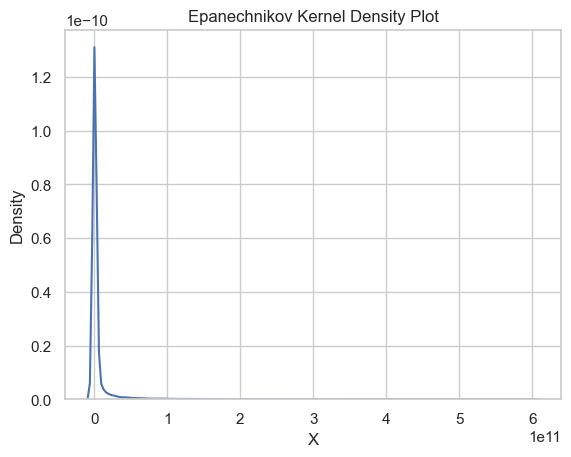

In [537]:
resample_number = 100000

kde_epa_resample = epanechnikov(data = X.flatten(), bandwidth = bandwith_X).sample(resample_number, method = 'order')
sns.kdeplot(kde_epa_resample)
plt.title('Epanechnikov Kernel Density Plot')
plt.xlabel('X')
plt.show()

----------------------------------------------------------------------
Membangun Event Loss Table (ELT)

Dari 2 KDE yg dapat digunakan --- pilih 1 KDE sesuai tugas

ARI = 50

In [542]:
# Membangun Event Loss Table (ELT)

# Kerugian dianggap mengikuti distribusi yang didapat dari Kernel Density Estimation (KDE)
# Rata-rata banyak kejadian gempa (Ni) PER TAHUN yang melebihi suatu moment magnitude dianggap mengikuti dist. Poisson
# Jadi, ELT yang diperoleh akan memiliki horizon waktu 1 tahun

# Dari 2 KDE yg dapat digunakan --- pilih 1 KDE sesuai tugas

##### Membangun ELT --- Gaussian KDE 
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 50 # Ditetapkan ARI = 50 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

start = time.time()
ELT = []

for event_id in total_loss.columns:
    Ni = np.random.poisson(lambd, 1)[0] # Banyak kejadian bersitribusi Poisson dengan lambda*t = 1 per ARI tahun
    event_id_sample = total_loss[event_id].values
    event_id_sample = event_id_sample[event_id_sample != 0]    
    if len(event_id_sample) == 0: # Jika total loss-nya semua bernilai nol
        Si = 0
        E_Xij = 0
        Std_Xij = 0
    else:
        if np.std(event_id_sample) == 0: # Jika suatu array bernilai sama semua
            Si = Ni*event_id_sample[0]
            E_Xij = event_id_sample[0]
            Std_Xij = 0
        else:
            bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
            kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape(-1, 1))
            simulation = kde_x.sample(1000000)
            E_Xij = simulation.mean()
            Std_Xij = simulation.std()
            Si = np.maximum(0, kde_x.sample(Ni)).sum()
    E_Si = E_Ni*E_Xij
    Var_Si = E_Ni*(Std_Xij**2) + Var_Ni*(E_Xij**2)
    ELT_i = np.array([Ni, Si, E_Xij, Std_Xij, E_Ni, Var_Ni, E_Si, Var_Si])
    ELT.append(ELT_i)

end = time.time()
print("Runtime: " + str(round(end - start, 2)) + "s")
ELT_Gauss = pd.DataFrame(ELT).set_axis(['frek', 'Si', 'E[Xij]', 'Std(Xij)', 'E[Ni]', 'Var(Ni)', 'E[Si]', 'Var(Si)'], axis = 1)
ELT_Gauss
##### Proses membangun ELT dengan Gaussian KDE selesai

Runtime: 28.8s


,frek,Si,E[Xij],Std(Xij),E[Ni],Var(Ni),E[Si],Var(Si)
0,0.0,0.0,2.776730e+08,1.513736e+08,0.02,0.02,5.553461e+06,2.000326e+15
1,0.0,0.0,6.512280e+08,9.544488e+08,0.02,0.02,1.302456e+07,2.670141e+16
2,0.0,0.0,8.972399e+09,1.813049e+10,0.02,0.02,1.794480e+08,8.184374e+18
3,0.0,0.0,1.200416e+10,2.251431e+10,0.02,0.02,2.400831e+08,1.301988e+19
4,0.0,0.0,1.944801e+09,4.205333e+09,0.02,0.02,3.889603e+07,4.293416e+17
...,...,...,...,...,...,...,...,...
298,0.0,0.0,5.822297e+09,1.179388e+10,0.02,0.02,1.164459e+08,3.459894e+18
299,0.0,0.0,2.105532e+08,1.134716e+08,0.02,0.02,4.211065e+06,1.144170e+15
300,0.0,0.0,1.713992e+09,3.518307e+09,0.02,0.02,3.427983e+07,3.063250e+17
301,0.0,0.0,5.792972e+08,7.779517e+08,0.02,0.02,1.158594e+07,1.881588e+16


In [544]:
# Simulasi Monte Carlo membangun ELT dan menghitung Total Aggregate Loss (S) sebanyak 1000 kali 

# Ingat bahwa nilai kerugian Xij disimulasikan dengan 2 KD. Jadi, simulasi juga menggunakan 2 KDE

##### Monte Carlo Total Aggregate Loss --- Gaussian KDE
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 50 # Ditetapkan ARI = 250 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

In [546]:

S = []
start = time.time()
num_S_sampling = 1000 # Banyak simulasi ELT


In [548]:
for iterate in range(num_S_sampling):
    Si_array = []
    for event_id in total_loss.columns:
        Ni = np.random.poisson(1/ARI, 1)[0]
        event_id_sample = total_loss[event_id].values
        event_id_sample = event_id_sample[event_id_sample != 0]
        if len(event_id_sample) == 0: # Jika total loss -nya semua bernilai nol
            Si = 0
        else :
            if np.std(event_id_sample) == 0: # Jika total loss yang tak nolnya semua bernilai sama
                Si = Ni*event_id_sample[0]
            else:
                if Ni == 0:
                    Si = 0
                else:
                    bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
                    kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape( -1 ,1))
                    Si = np.maximum(0, kde_x.sample(Ni)).sum ()
        Si_array.append (Si)
    S.append(np.array(Si_array).sum ())
    print('Iterasi ke -' + str(iterate +1) + 'selesai') if (iterate +1) %100 == 0 else None

print()
print("Runtime: " + str(round(time.time() - start ,2)) + "s")

Iterasi ke -100selesai
Iterasi ke -200selesai
Iterasi ke -300selesai
Iterasi ke -400selesai
Iterasi ke -500selesai
Iterasi ke -600selesai
Iterasi ke -700selesai
Iterasi ke -800selesai
Iterasi ke -900selesai
Iterasi ke -1000selesai

Runtime: 43.0s


(0.0, 250000000.0)

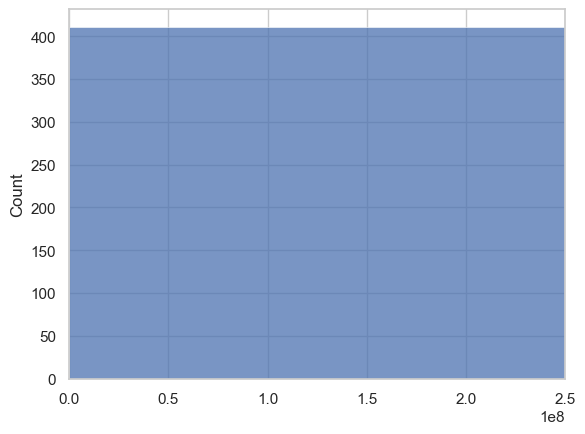

In [550]:
S = pd.DataFrame({'S': S})
sns.histplot(S['S'].values)
plt.xlim([0, 0.25*10**9])
##### Proses membangun nilai S berdasarkan Monte Carlo dengan Gaussian KDE selesai

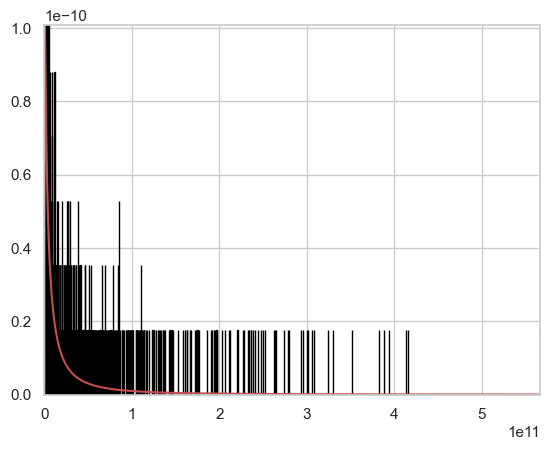

In [552]:
# Memodelkan 1000 nilai S hasil Monte Carlo yang diasumsikan mengikuti suatu distribusi parametrik

# Dalam kasus ini, kita modelkan dengan distribusi binomial-lognormal Two-Part Model
from scipy.stats import lognorm

# Hanya nilai tak nol pada data yang digunakan dalam estimasi parameter
S_non0 = S[(S.T != 0).any()]

# Proses estimasi parameter
def blnorm_mle(x): 

    non0 = np.count_nonzero(x)
    theta = np.round(1 - non0/1000, decimals = 3) # Peluang tidak nol
    shape, loc, scale = lognorm.fit(x, floc = 0)
    
    return theta, shape, scale

theta, shape, scale = blnorm_mle(S_non0)
theta, shape, scale # Hasil estimasi parameter

# Definisikan pdf distribusi binomial-lognormal Two-Part Model
def pdf_blnorm(x):
    if(x.any() == 0): 
        return theta
    else: 
        return (1 - theta)*lognorm.pdf(x, s = shape, loc = 0, scale = scale)

# Membentuk histogram untuk 1000 nilai S dan menggambar pdf lognormal
x = np.linspace(0, S.max(), num = 10000)
x0 = np.array([0.0000001*10**8 for i in range (10000)])
y0 = np.linspace(0, 1-theta, 10000)
plt.hist(S, bins = 10000, color = 'b', edgecolor = 'black', density = True)
plt.xlim(xmin = 0, xmax = np.max(S))
plt.ylim(ymin = 0, ymax = np.max(pdf_blnorm(x)))
plt.plot(x, pdf_blnorm(x), color = 'r')
#plt.scatter(0, theta, color = 'r')
#plt.plot(x0, y0, color = 'r', linewidth = 5)
plt.show()

#----------------------------------------------------------------------

In [554]:
# Membangkitkan sampel yang memiliki distribusi Bernoulli-Lognormal Two-Part Model seperti di atas
# Hal ini digunakan untuk mengestimasi VaR dan TVaR

sample = []

for i in range (1000):
    u = np.random.uniform(0 ,1)
    if u > theta:
        sample.append(lognorm.rvs(s = shape, loc = 0, scale = scale, size = 1, random_state = None)[0])
    elif u <= theta:
        sample.append(0)

sample = np.array(sample).flatten ()
sample

# Cramer-von Mises Hypothesis Two Sample Test
# Perhatikan bahwa Uji Two Sample ini menggunakan seluruh nilai termasuk yang 0 juga
cvm2 = stats.cramervonmises_2samp(np.array(S). flatten(), sample)
cvm2.statistic, cvm2.pvalue # Cramer-von Mises Hypothesis Two - Sample Test

(0.506926749999991, 0.03825388789270778)

In [556]:
# Mencari Var dan Tvar dari Bernoulli-Lognormal Two-Part Model

from scipy import integrate

def rm(p, theta, shape, scale): # Theta adalah peluang nol

    if (p < theta):
        var = 0
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), theta, 1)[0]/(1-p)
    elif (p >= theta):
        var = lognorm(s = shape, loc = 0, scale = scale).ppf((p + (1 - theta) - 1)/(1 - theta))
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), p, 1)[0]/(1-p)
    return var , tvar

p = 0.95   # originally typed in with input(); change it to read another level 
# Ini dapat dimodifikasi, apakah menggunakan input user atau tidak
# Sebagai contoh, Anda langsung menghitung VaR dan TVaR 95%, 99,75%, dan 99%
var, tvar = rm(p, theta, shape, scale)
var, tvar

Masukkan nilai peluang yang ingin dicari nilai VaR dan TVaR-nya (0 ,1):  0.95


(185217034830.4975, 522855022422.4089)

ARI 100

In [558]:
# Membangun Event Loss Table (ELT)

# Kerugian dianggap mengikuti distribusi yang didapat dari Kernel Density Estimation (KDE)
# Rata-rata banyak kejadian gempa (Ni) PER TAHUN yang melebihi suatu moment magnitude dianggap mengikuti dist. Poisson
# Jadi, ELT yang diperoleh akan memiliki horizon waktu 1 tahun

# Dari 2 KDE yg dapat digunakan --- pilih 1 KDE sesuai tugas

##### Membangun ELT --- Gaussian KDE 
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 100 # Ditetapkan ARI = 250 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

start = time.time()
ELT = []

for event_id in total_loss.columns:
    Ni = np.random.poisson(lambd, 1)[0] # Banyak kejadian bersitribusi Poisson dengan lambda*t = 1 per ARI tahun
    event_id_sample = total_loss[event_id].values
    event_id_sample = event_id_sample[event_id_sample != 0]    
    if len(event_id_sample) == 0: # Jika total loss-nya semua bernilai nol
        Si = 0
        E_Xij = 0
        Std_Xij = 0
    else:
        if np.std(event_id_sample) == 0: # Jika suatu array bernilai sama semua
            Si = Ni*event_id_sample[0]
            E_Xij = event_id_sample[0]
            Std_Xij = 0
        else:
            bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
            kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape(-1, 1))
            simulation = kde_x.sample(1000000)
            E_Xij = simulation.mean()
            Std_Xij = simulation.std()
            Si = np.maximum(0, kde_x.sample(Ni)).sum()
    E_Si = E_Ni*E_Xij
    Var_Si = E_Ni*(Std_Xij**2) + Var_Ni*(E_Xij**2)
    ELT_i = np.array([Ni, Si, E_Xij, Std_Xij, E_Ni, Var_Ni, E_Si, Var_Si])
    ELT.append(ELT_i)

end = time.time()
print("Runtime: " + str(round(end - start, 2)) + "s")
ELT_Gauss = pd.DataFrame(ELT).set_axis(['frek', 'Si', 'E[Xij]', 'Std(Xij)', 'E[Ni]', 'Var(Ni)', 'E[Si]', 'Var(Si)'], axis = 1)
ELT_Gauss
##### Proses membangun ELT dengan Gaussian KDE selesai

Runtime: 28.71s


,frek,Si,E[Xij],Std(Xij),E[Ni],Var(Ni),E[Si],Var(Si)
0,0.0,0.0,2.776100e+08,1.511550e+08,0.01,0.01,2.776100e+06,9.991516e+14
1,0.0,0.0,6.506892e+08,9.513652e+08,0.01,0.01,6.506892e+06,1.328492e+16
2,0.0,0.0,8.880571e+09,1.800606e+10,0.01,0.01,8.880571e+07,4.030828e+18
3,0.0,0.0,1.197904e+10,2.249823e+10,0.01,0.01,1.197904e+08,6.496675e+18
4,0.0,0.0,1.948271e+09,4.200041e+09,0.01,0.01,1.948271e+07,2.143611e+17
...,...,...,...,...,...,...,...,...
298,0.0,0.0,5.856871e+09,1.184688e+10,0.01,0.01,5.856871e+07,1.746515e+18
299,0.0,0.0,2.106309e+08,1.133310e+08,0.01,0.01,2.106309e+06,5.720928e+14
300,0.0,0.0,1.718541e+09,3.526194e+09,0.01,0.01,1.718541e+07,1.538742e+17
301,0.0,0.0,5.776679e+08,7.720637e+08,0.01,0.01,5.776679e+06,9.297825e+15


In [560]:
# Simulasi Monte Carlo membangun ELT dan menghitung Total Aggregate Loss (S) sebanyak 1000 kali 

# Ingat bahwa nilai kerugian Xij disimulasikan dengan 2 KD. Jadi, simulasi juga menggunakan 2 KDE

##### Monte Carlo Total Aggregate Loss --- Gaussian KDE
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 100 # Ditetapkan ARI = 250 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

In [562]:
S = []
start = time.time()
num_S_sampling = 1000 # Banyak simulasi ELT

In [564]:
for iterate in range(num_S_sampling):
    Si_array = []
    for event_id in total_loss.columns:
        Ni = np.random.poisson(1/ARI, 1)[0]
        event_id_sample = total_loss[event_id].values
        event_id_sample = event_id_sample[event_id_sample != 0]
        if len(event_id_sample) == 0: # Jika total loss -nya semua bernilai nol
            Si = 0
        else :
            if np.std(event_id_sample) == 0: # Jika total loss yang tak nolnya semua bernilai sama
                Si = Ni*event_id_sample[0]
            else:
                if Ni == 0:
                    Si = 0
                else:
                    bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
                    kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape( -1 ,1))
                    Si = np.maximum(0, kde_x.sample(Ni)).sum ()
        Si_array.append (Si)
    S.append(np.array(Si_array).sum ())
    print('Iterasi ke -' + str(iterate +1) + 'selesai') if (iterate +1) %100 == 0 else None

print()
print("Runtime: " + str(round(time.time() - start ,2)) + "s")

Iterasi ke -100selesai
Iterasi ke -200selesai
Iterasi ke -300selesai
Iterasi ke -400selesai
Iterasi ke -500selesai
Iterasi ke -600selesai
Iterasi ke -700selesai
Iterasi ke -800selesai
Iterasi ke -900selesai
Iterasi ke -1000selesai

Runtime: 39.53s


(0.0, 250000000.0)

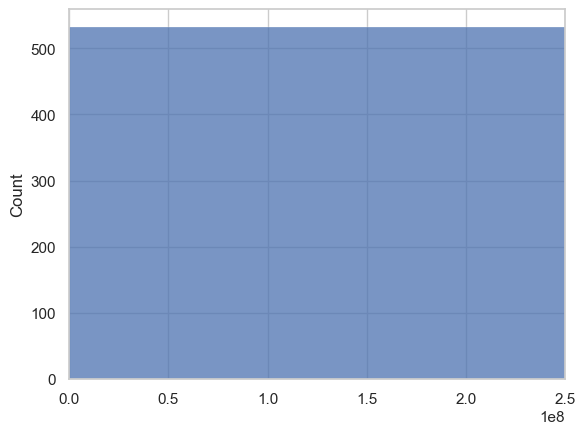

In [565]:
S = pd.DataFrame({'S': S})
sns.histplot(S['S'].values)
plt.xlim([0, 0.25*10**9])
##### Proses membangun nilai S berdasarkan Monte Carlo dengan Gaussian KDE selesai

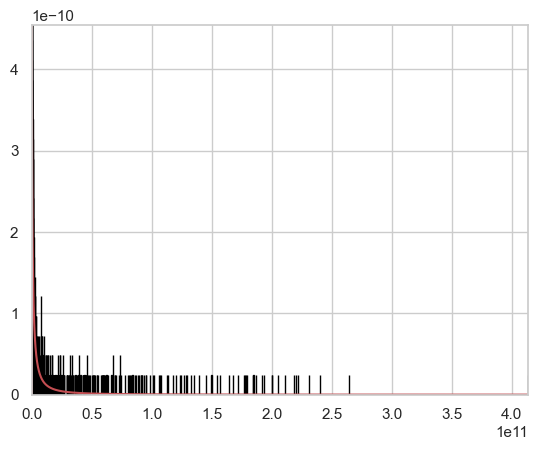

In [570]:
# Memodelkan 1000 nilai S hasil Monte Carlo yang diasumsikan mengikuti suatu distribusi parametrik

# Dalam kasus ini, kita modelkan dengan distribusi binomial-lognormal Two-Part Model
from scipy.stats import lognorm

# Hanya nilai tak nol pada data yang digunakan dalam estimasi parameter
S_non0 = S[(S.T != 0).any()]

# Proses estimasi parameter
def blnorm_mle(x): 

    non0 = np.count_nonzero(x)
    theta = np.round(1 - non0/1000, decimals = 3) # Peluang tidak nol
    shape, loc, scale = lognorm.fit(x, floc = 0)
    
    return theta, shape, scale

theta, shape, scale = blnorm_mle(S_non0)
theta, shape, scale # Hasil estimasi parameter

# Definisikan pdf distribusi binomial-lognormal Two-Part Model
def pdf_blnorm(x):
    if(x.any() == 0): 
        return theta
    else: 
        return (1 - theta)*lognorm.pdf(x, s = shape, loc = 0, scale = scale)

# Membentuk histogram untuk 1000 nilai S dan menggambar pdf lognormal
x = np.linspace(0, S.max(), num = 10000)
x0 = np.array([0.0000001*10**8 for i in range (10000)])
y0 = np.linspace(0, 1-theta, 10000)
plt.hist(S, bins = 10000, color = 'b', edgecolor = 'black', density = True)
plt.xlim(xmin = 0, xmax = np.max(S))
plt.ylim(ymin = 0, ymax = np.max(pdf_blnorm(x)))
plt.plot(x, pdf_blnorm(x), color = 'r')
#plt.scatter(0, theta, color = 'r')
#plt.plot(x0, y0, color = 'r', linewidth = 5)
plt.show()

#----------------------------------------------------------------------

In [350]:
# Membangkitkan sampel yang memiliki distribusi Bernoulli-Lognormal Two-Part Model seperti di atas
# Hal ini digunakan untuk mengestimasi VaR dan TVaR

sample = []

for i in range (1000):
    u = np.random.uniform(0 ,1)
    if u > theta:
        sample.append(lognorm.rvs(s = shape, loc = 0, scale = scale, size = 1, random_state = None)[0])
    elif u <= theta:
        sample.append(0)

sample = np.array(sample).flatten ()
sample

# Cramer-von Mises Hypothesis Two Sample Test
# Perhatikan bahwa Uji Two Sample ini menggunakan seluruh nilai termasuk yang 0 juga
cvm2 = stats.cramervonmises_2samp(np.array(S). flatten(), sample)
cvm2.statistic, cvm2.pvalue # Cramer-von Mises Hypothesis Two - Sample Test

(0.31340899999997873, 0.12400616846437917)

In [574]:
# Mencari Var dan Tvar dari Bernoulli-Lognormal Two-Part Model

from scipy import integrate

def rm(p, theta, shape, scale): # Theta adalah peluang nol

    if (p < theta):
        var = 0
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), theta, 1)[0]/(1-p)
    elif (p >= theta):
        var = lognorm(s = shape, loc = 0, scale = scale).ppf((p + (1 - theta) - 1)/(1 - theta))
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), p, 1)[0]/(1-p)
    return var , tvar

p = 0.95   # originally typed in with input(); change it to read another level 
# Ini dapat dimodifikasi, apakah menggunakan input user atau tidak
# Sebagai contoh, Anda langsung menghitung VaR dan TVaR 95%, 99,75%, dan 99%
var, tvar = rm(p, theta, shape, scale)
var, tvar

Masukkan nilai peluang yang ingin dicari nilai VaR dan TVaR-nya (0 ,1):  0.95


(74067713408.44743, 265122192885.83823)

ARI = 250

In [576]:
# Membangun Event Loss Table (ELT)

# Kerugian dianggap mengikuti distribusi yang didapat dari Kernel Density Estimation (KDE)
# Rata-rata banyak kejadian gempa (Ni) PER TAHUN yang melebihi suatu moment magnitude dianggap mengikuti dist. Poisson
# Jadi, ELT yang diperoleh akan memiliki horizon waktu 1 tahun

# Dari 2 KDE yg dapat digunakan --- pilih 1 KDE sesuai tugas

##### Membangun ELT --- Gaussian KDE 
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 250 # Ditetapkan ARI = 50 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

start = time.time()
ELT = []

for event_id in total_loss.columns:
    Ni = np.random.poisson(lambd, 1)[0] # Banyak kejadian bersitribusi Poisson dengan lambda*t = 1 per ARI tahun
    event_id_sample = total_loss[event_id].values
    event_id_sample = event_id_sample[event_id_sample != 0]    
    if len(event_id_sample) == 0: # Jika total loss-nya semua bernilai nol
        Si = 0
        E_Xij = 0
        Std_Xij = 0
    else:
        if np.std(event_id_sample) == 0: # Jika suatu array bernilai sama semua
            Si = Ni*event_id_sample[0]
            E_Xij = event_id_sample[0]
            Std_Xij = 0
        else:
            bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
            kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape(-1, 1))
            simulation = kde_x.sample(1000000)
            E_Xij = simulation.mean()
            Std_Xij = simulation.std()
            Si = np.maximum(0, kde_x.sample(Ni)).sum()
    E_Si = E_Ni*E_Xij
    Var_Si = E_Ni*(Std_Xij**2) + Var_Ni*(E_Xij**2)
    ELT_i = np.array([Ni, Si, E_Xij, Std_Xij, E_Ni, Var_Ni, E_Si, Var_Si])
    ELT.append(ELT_i)

end = time.time()
print("Runtime: " + str(round(end - start, 2)) + "s")
ELT_Gauss = pd.DataFrame(ELT).set_axis(['frek', 'Si', 'E[Xij]', 'Std(Xij)', 'E[Ni]', 'Var(Ni)', 'E[Si]', 'Var(Si)'], axis = 1)
ELT_Gauss
##### Proses membangun ELT dengan Gaussian KDE selesai

Runtime: 28.82s


,frek,Si,E[Xij],Std(Xij),E[Ni],Var(Ni),E[Si],Var(Si)
0,0.0,0.0,2.773393e+08,1.511009e+08,0.004,0.004,1.109357e+06,3.989943e+14
1,0.0,0.0,6.527216e+08,9.550080e+08,0.004,0.004,2.610887e+06,5.352344e+15
2,0.0,0.0,8.905612e+09,1.800940e+10,0.004,0.004,3.562245e+07,1.614594e+18
3,0.0,0.0,1.193895e+10,2.248686e+10,0.004,0.004,4.775580e+07,2.592790e+18
4,0.0,0.0,1.946329e+09,4.205572e+09,0.004,0.004,7.785315e+06,8.590012e+16
...,...,...,...,...,...,...,...,...
298,0.0,0.0,5.853876e+09,1.184498e+10,0.004,0.004,2.341550e+07,6.982859e+17
299,0.0,0.0,2.105624e+08,1.131958e+08,0.004,0.004,8.422498e+05,2.285993e+14
300,0.0,0.0,1.706559e+09,3.508533e+09,0.004,0.004,6.826237e+06,6.088860e+16
301,0.0,0.0,5.776955e+08,7.757465e+08,0.004,0.004,2.310782e+06,3.742059e+15


In [578]:
# Simulasi Monte Carlo membangun ELT dan menghitung Total Aggregate Loss (S) sebanyak 1000 kali 

# Ingat bahwa nilai kerugian Xij disimulasikan dengan 2 KD. Jadi, simulasi juga menggunakan 2 KDE

##### Monte Carlo Total Aggregate Loss --- Gaussian KDE
##### NB: Hapus bagian proses KDE Epanechnikov jika ditugaskan menggunakan Gaussian KDE 

ARI = 250 # Ditetapkan ARI = 250 tahun. Ini bisa diganti
lambd = 1/ARI # Frekuensi kejadian bencana adalah 1/ARI = 1/250 per tahun. Ini adalah parameter lambda di dist. Poisson
E_Ni = lambd # Ekspektasi dist Poisson
Var_Ni = lambd # Varians dist Poisson

In [580]:
S = []
start = time.time()
num_S_sampling = 1000 # Banyak simulasi ELT

In [582]:
for iterate in range(num_S_sampling):
    Si_array = []
    for event_id in total_loss.columns:
        Ni = np.random.poisson(1/ARI, 1)[0]
        event_id_sample = total_loss[event_id].values
        event_id_sample = event_id_sample[event_id_sample != 0]
        if len(event_id_sample) == 0: # Jika total loss -nya semua bernilai nol
            Si = 0
        else :
            if np.std(event_id_sample) == 0: # Jika total loss yang tak nolnya semua bernilai sama
                Si = Ni*event_id_sample[0]
            else:
                if Ni == 0:
                    Si = 0
                else:
                    bandwidth = 1.06*np.std(event_id_sample)*len(event_id_sample)**(-0.2) # Aturan Scott
                    kde_x = KernelDensity(bandwidth = bandwidth, kernel = 'gaussian').fit(event_id_sample.reshape( -1 ,1))
                    Si = np.maximum(0, kde_x.sample(Ni)).sum ()
        Si_array.append (Si)
    S.append(np.array(Si_array).sum ())
    print('Iterasi ke -' + str(iterate +1) + 'selesai') if (iterate +1) %100 == 0 else None

print()
print("Runtime: " + str(round(time.time() - start ,2)) + "s")

Iterasi ke -100selesai
Iterasi ke -200selesai
Iterasi ke -300selesai
Iterasi ke -400selesai
Iterasi ke -500selesai
Iterasi ke -600selesai
Iterasi ke -700selesai
Iterasi ke -800selesai
Iterasi ke -900selesai
Iterasi ke -1000selesai

Runtime: 35.76s


(0.0, 250000000.0)

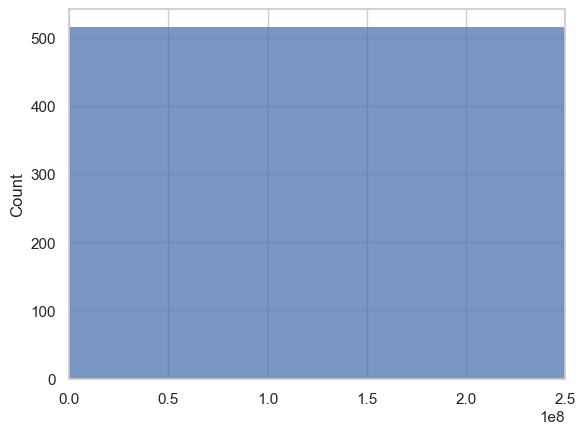

In [583]:
S = pd.DataFrame({'S': S})
sns.histplot(S['S'].values)
plt.xlim([0, 0.25*10**9])
##### Proses membangun nilai S berdasarkan Monte Carlo dengan Gaussian KDE selesai

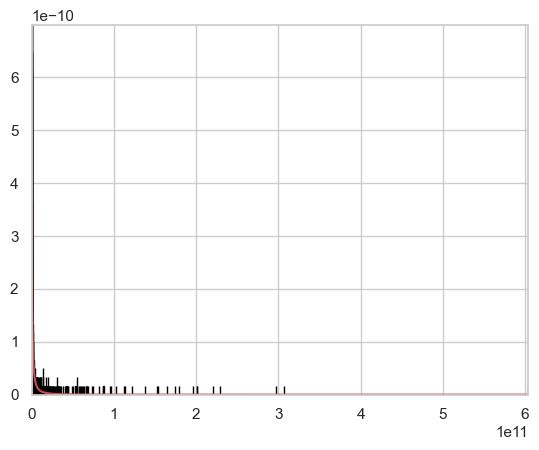

In [586]:
# Memodelkan 1000 nilai S hasil Monte Carlo yang diasumsikan mengikuti suatu distribusi parametrik

# Dalam kasus ini, kita modelkan dengan distribusi binomial-lognormal Two-Part Model
from scipy.stats import lognorm

# Hanya nilai tak nol pada data yang digunakan dalam estimasi parameter
S_non0 = S[(S.T != 0).any()]

# Proses estimasi parameter
def blnorm_mle(x): 

    non0 = np.count_nonzero(x)
    theta = np.round(1 - non0/1000, decimals = 3) # Peluang tidak nol
    shape, loc, scale = lognorm.fit(x, floc = 0)
    
    return theta, shape, scale

theta, shape, scale = blnorm_mle(S_non0)
theta, shape, scale # Hasil estimasi parameter

# Definisikan pdf distribusi binomial-lognormal Two-Part Model
def pdf_blnorm(x):
    if(x.any() == 0): 
        return theta
    else: 
        return (1 - theta)*lognorm.pdf(x, s = shape, loc = 0, scale = scale)

# Membentuk histogram untuk 1000 nilai S dan menggambar pdf lognormal
x = np.linspace(0, S.max(), num = 10000)
x0 = np.array([0.0000001*10**8 for i in range (10000)])
y0 = np.linspace(0, 1-theta, 10000)
plt.hist(S, bins = 10000, color = 'b', edgecolor = 'black', density = True)
plt.xlim(xmin = 0, xmax = np.max(S))
plt.ylim(ymin = 0, ymax = np.max(pdf_blnorm(x)))
plt.plot(x, pdf_blnorm(x), color = 'r')
plt.show()

#----------------------------------------------------------------------

In [367]:
# Membangkitkan sampel yang memiliki distribusi Bernoulli-Lognormal Two-Part Model seperti di atas
# Hal ini digunakan untuk mengestimasi VaR dan TVaR

sample = []

for i in range (1000):
    u = np.random.uniform(0 ,1)
    if u > theta:
        sample.append(lognorm.rvs(s = shape, loc = 0, scale = scale, size = 1, random_state = None)[0])
    elif u <= theta:
        sample.append(0)

sample = np.array(sample).flatten ()
sample

# Cramer-von Mises Hypothesis Two Sample Test
# Perhatikan bahwa Uji Two Sample ini menggunakan seluruh nilai termasuk yang 0 juga
cvm2 = stats.cramervonmises_2samp(np.array(S). flatten(), sample)
cvm2.statistic, cvm2.pvalue # Cramer-von Mises Hypothesis Two - Sample Test

(0.4195219999999722, 0.06420268865685752)

In [369]:
# Mencari Var dan Tvar dari Bernoulli-Lognormal Two-Part Model

from scipy import integrate

def rm(p, theta, shape, scale): # Theta adalah peluang nol

    if (p < theta):
        var = 0
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), theta, 1)[0]/(1-p)
    elif (p >= theta):
        var = lognorm(s = shape, loc = 0, scale = scale).ppf((p + (1 - theta) - 1)/(1 - theta))
        tvar = integrate.quad(lambda x: lognorm(s = shape, loc = 0, scale = scale).ppf((x + (1 - theta) - 1)/(1 - theta)), p, 1)[0]/(1-p)
    return var , tvar

p = 0.95   # originally typed in with input(); change it to read another level 
# Ini dapat dimodifikasi, apakah menggunakan input user atau tidak
# Sebagai contoh, Anda langsung menghitung VaR dan TVaR 95%, 99,75%, dan 99%
var, tvar = rm(p, theta, shape, scale)
var, tvar

Masukkan nilai peluang yang ingin dicari nilai VaR dan TVaR-nya (0 ,1):  0.95


(20883595573.440773, 81136402328.783)